# Analysis of TEcount output (DESeq2)

# Imports

In [1]:
version

               _                           
platform       aarch64-apple-darwin20      
arch           aarch64                     
os             darwin20                    
system         aarch64, darwin20           
status                                     
major          4                           
minor          5.0                         
year           2025                        
month          04                          
day            11                          
svn rev        88135                       
language       R                           
version.string R version 4.5.0 (2025-04-11)
nickname       How About a Twenty-Six      

In [2]:
setwd("..")

In [3]:
# The R kernel activates the parent renv project via .Rprofile.
renv::status()

The following package(s) are in an inconsistent state:

 package    installed recorded used
 beeswarm   y         n        y   
 ggbeeswarm y         n        y   
 openxlsx   n         n        y   
 vipor      y         n        y   

See `?renv::status` for advice on resolving these issues.


In [4]:
renv::restore()
renv::status()

- The library is already synchronized with the lockfile.
The following package(s) are in an inconsistent state:

 package    installed recorded used
 beeswarm   y         n        y   
 ggbeeswarm y         n        y   
 openxlsx   n         n        y   
 vipor      y         n        y   

See `?renv::status` for advice on resolving these issues.


In [5]:
library(DESeq2)
library(dplyr)
library(tidyr)
library(ggplot2)
library(pheatmap)
library(RColorBrewer)
library(clusterProfiler)
library(org.Mm.eg.db)
library(enrichplot)
library(DOSE)
library(biomaRt)
library(svglite)
library(ggbeeswarm)


# Set working directory
if (basename(getwd()) != "TECounts" && dir.exists("TECounts")) {
  setwd("TECounts")
}

Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min



Attaching package: ‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The follo

# Annotation & Filtering

In [7]:
create_count_matrix <- function(count_dir = "TEcounts_output") {
  # List all count table files
  count_files <- list.files(count_dir, pattern = "*.cntTable", full.names = TRUE)
  
  # Filter out low quality samples (l1-5)
  count_files <- count_files[!grepl("l1-5", basename(count_files))]
  
  cat("Found", length(count_files), "count files\n")
  
  # Read and combine all count tables
  count_list <- lapply(count_files, function(file) {
    counts <- read.table(file, header = TRUE, sep = "\t")
    colnames(counts) <- c("gene_id", "counts")
    
    # Clean gene IDs
    counts$gene_id <- gsub('"', '', counts$gene_id)
    
    # Extract sample name
    sample_name <- gsub(".cntTable", "", basename(file))
    
    # Return with sample name
    colnames(counts)[2] <- sample_name
    return(counts)
  })
  
  # Merge all samples
  count_matrix <- Reduce(function(x, y) {
    merge(x, y, by = "gene_id", all = TRUE)
  }, count_list)
  
  # Replace NA with 0
  count_matrix[is.na(count_matrix)] <- 0
  
  # Convert to data frame and set gene_id as rownames
  count_matrix <- as.data.frame(count_matrix)
  rownames(count_matrix) <- count_matrix$gene_id
  count_matrix$gene_id <- NULL
  
  # Convert to numeric matrix for DESeq2
  count_matrix <- as.matrix(count_matrix)
  
  cat("Count matrix dimensions:", dim(count_matrix), "\n")
  cat("Sample names:", colnames(count_matrix), "\n")
  
  return(count_matrix)
}

# Function to annotate and categorize gene IDs
annotate_gene_ids <- function(gene_ids) {
  # Create annotation data frame
  annotations <- data.frame(
    gene_id = gene_ids,
    gene_id_clean = gsub("\\.[0-9]+$", "", gene_ids),  # Remove version numbers
    category = "unknown",
    element_type = "unknown",
    family = "unknown",
    stringsAsFactors = FALSE
  )
  
  # Categorize based on ID patterns
  annotations$category <- case_when(
    # Standard Ensembl genes
    grepl("^ENSMUSG", annotations$gene_id_clean) ~ "protein_coding",
    
    # RNA elements
    grepl(":RNA:", annotations$gene_id) ~ "rna_element",
    grepl("^7SK", annotations$gene_id) ~ "rna_element",
    
    # SINE elements
    grepl(":SINE", annotations$gene_id) ~ "sine_element",
    grepl(":Alu", annotations$gene_id) ~ "sine_element",
    grepl("^B[0-9]", annotations$gene_id) ~ "sine_element",
    
    # LINE elements
    grepl(":LINE", annotations$gene_id) ~ "line_element",
    grepl("^L1", annotations$gene_id) ~ "line_element",
    
    # LTR/Retroviral elements
    grepl(":LTR:", annotations$gene_id) ~ "ltr_element",
    grepl(":ERV", annotations$gene_id) ~ "ltr_element",
    grepl("^BGLII", annotations$gene_id) ~ "ltr_element",
    
    # DNA transposons
    grepl(":hAT", annotations$gene_id) ~ "dna_transposon",
    grepl("^Charlie", annotations$gene_id) ~ "dna_transposon",
    grepl("^Arthur", annotations$gene_id) ~ "dna_transposon",
    grepl("^BLACKJACK", annotations$gene_id) ~ "dna_transposon",
    
    # Other repetitive elements
    grepl(":CR1", annotations$gene_id) ~ "other_repetitive",
    grepl("^CR1_", annotations$gene_id) ~ "other_repetitive",
    grepl("^CYRA", annotations$gene_id) ~ "other_repetitive",
    
    TRUE ~ "other"
  )
  
  # Extract element family information
  annotations$family <- case_when(
    grepl("^B[0-9]", annotations$gene_id) ~ "B-family_SINE",
    grepl("^Charlie", annotations$gene_id) ~ "Charlie_hAT",
    grepl("^Arthur", annotations$gene_id) ~ "Arthur_hAT",
    grepl("^L1", annotations$gene_id) ~ "L1_LINE",
    grepl("^BGLII", annotations$gene_id) ~ "BGLII_ERV",
    grepl("^7SK", annotations$gene_id) ~ "7SK_RNA",
    TRUE ~ "other"
  )
  
  # Extract element type
  annotations$element_type <- case_when(
    annotations$category == "protein_coding" ~ "gene",
    annotations$category == "rna_element" ~ "rna",
    annotations$category == "sine_element" ~ "sine",
    annotations$category == "line_element" ~ "line",
    annotations$category == "ltr_element" ~ "ltr",
    annotations$category == "dna_transposon" ~ "dna_transposon",
    annotations$category == "other_repetitive" ~ "repetitive",
    TRUE ~ "other"
  )
  
  return(annotations)
}

# Function to get gene names and descriptions from Ensembl
get_gene_names <- function(ensembl_ids, cache_file = "RNAseq_results/gene_annotations_cache.rds") {
  # Clean Ensembl IDs (remove version numbers)
  clean_ids <- gsub("\\.[0-9]+$", "", ensembl_ids)
  
  # Get unique IDs
  unique_ids <- unique(clean_ids)
  
  cat("Fetching gene names for", length(unique_ids), "unique Ensembl IDs...\n")
  
  # Check if cache file exists
  if (file.exists(cache_file)) {
    cat("Loading gene annotations from cache file:", cache_file, "\n")
    cached_data <- readRDS(cache_file)
    cat("Loaded", nrow(cached_data), "gene annotations from cache\n")
    return(cached_data)
  }
  
  # List of Ensembl mirrors to try
  ensembl_hosts <- c(
    "https://www.ensembl.org",
    "https://useast.ensembl.org",
    "https://uswest.ensembl.org",
    "https://asia.ensembl.org"
  )
  
  gene_info <- NULL
  
  for (host in ensembl_hosts) {
    cat("Trying Ensembl host:", host, "\n")
    
    tryCatch({
      # Connect to Ensembl mouse database
      mart <- useMart("ensembl", dataset = "mmusculus_gene_ensembl", host = host)
      
      # Get gene information
      gene_info <- getBM(
        attributes = c("ensembl_gene_id", "external_gene_name", "gene_biotype", "description"),
        filters = "ensembl_gene_id",
        values = unique_ids,
        mart = mart
      )
      
      if (!is.null(gene_info) && nrow(gene_info) > 0) {
        cat("Successfully retrieved information for", nrow(gene_info), "genes from", host, "\n")
        
        # Save to cache
        saveRDS(gene_info, cache_file)
        cat("Saved gene annotations to cache:", cache_file, "\n")
        
        return(gene_info)
      }
      
    }, error = function(e) {
      cat("Error with host", host, ":", e$message, "\n")
    })
  }
  
  # If all hosts failed, create empty data frame with correct structure
  if (is.null(gene_info)) {
    cat("WARNING: All Ensembl hosts failed. Creating empty annotation data frame.\n")
    cat("Analysis will continue but gene names will not be available.\n")
    
    gene_info <- data.frame(
      ensembl_gene_id = character(0),
      external_gene_name = character(0),
      gene_biotype = character(0),
      description = character(0),
      stringsAsFactors = FALSE
    )
  }
  
  return(gene_info)
}

# Function to filter genes (remove low counts)
filter_low_counts <- function(count_matrix, min_count = 10, min_samples = 2) {
  # Keep genes with at least min_count reads in at least min_samples
  keep <- rowSums(count_matrix >= min_count) >= min_samples
  filtered_matrix <- count_matrix[keep, ]
  
  cat("Original genes:", nrow(count_matrix), "\n")
  cat("Genes after filtering:", nrow(filtered_matrix), "\n")
  
  return(filtered_matrix)
}

# DESeq2 & plotting functions 

In [8]:
run_deseq2 <- function(count_matrix, metadata, design_formula = ~ group) {
  # Create DESeq2 dataset
  dds <- DESeqDataSetFromMatrix(
    countData = round(count_matrix),
    colData = metadata,
    design = design_formula
  )
  
  # Set reference level (adjust based on your groups)
  dds$group <- relevel(dds$group, ref =  "LFD_1")
  
  # Run DESeq2
  dds <- DESeq(dds)
  
  return(dds)
}

# Function to run DESeq2 on all pairwise comparisons
run_all_deseq2_comparisons <- function(dds, metadata, gene_annotations = NULL, alpha = 0.05, lfc_threshold = 0) {
  groups <- levels(metadata$group)
  n_groups <- length(groups)
  
  cat("Running DESeq2 on all pairwise comparisons...\n")
  cat("Groups:", paste(groups, collapse = ", "), "\n")
  
  all_results <- list()
  
  # Create all pairwise combinations
  for (i in 1:(n_groups-1)) {
    for (j in (i+1):n_groups) {
      group1 <- groups[i]
      group2 <- groups[j]
      
      cat("Comparing", group1, "vs", group2, "...\n")
      
      # Create contrast
      contrast <- c("group", group2, group1)
      
      # Get results with error handling
      tryCatch({
        res <- results(dds, 
                       contrast = contrast,
                       alpha = alpha,
                       lfcThreshold = lfc_threshold)
        
        # Check if results are valid
        if (is.null(res) || nrow(res) == 0) {
          cat("  No results obtained for this comparison\n")
          next
        }
        
        # Convert to data frame and add metadata
        res_df <- as.data.frame(res)
        res_df$gene_id <- rownames(res_df)
        res_df$comparison <- paste(group2, "vs", group1)
        res_df$group1 <- group1
        res_df$group2 <- group2
        
        # Handle NA values in padj and log2FoldChange
        res_df$padj[is.na(res_df$padj)] <- 1  # Set NA p-values to 1 (not significant)
        res_df$log2FoldChange[is.na(res_df$log2FoldChange)] <- 0  # Set NA fold changes to 0
        
        # Add significance column
        res_df$significant <- ifelse(res_df$padj < alpha & abs(res_df$log2FoldChange) > lfc_threshold, 
                                    "Yes", "No")
        
        # Add gene annotations if provided
        if (!is.null(gene_annotations)) {
          # Merge with gene annotations
          res_df <- res_df %>%
            left_join(gene_annotations[, c("gene_id", "external_gene_name", "category", "element_type", "family", "gene_biotype")], 
                     by = "gene_id")
          
          # Create a display name column (gene name if available, otherwise Ensembl ID)
          res_df$display_name <- ifelse(!is.na(res_df$external_gene_name) & res_df$external_gene_name != "", 
                                       res_df$external_gene_name, 
                                       res_df$gene_id)
        }
        
        # Order by adjusted p-value
        res_df <- res_df[order(res_df$padj), ]
        
        # Store results
        comparison_name <- paste(group2, "_vs_", group1, sep = "")
        all_results[[comparison_name]] <- res_df
        
        # Save individual comparison results with gene names
        filename <- paste0("RNAseq_results/DEG/", comparison_name, "_significant_degs.csv")
        write.csv(res_df, filename, row.names = FALSE)
        
        # Count significant genes properly
        sig_count <- sum(res_df$significant == "Yes", na.rm = TRUE)
        cat("  Significant genes:", sig_count, "\n")
        cat("  Total genes:", nrow(res_df), "\n")
        cat("  Upregulated:", sum(res_df$significant == "Yes" & res_df$log2FoldChange > 0, na.rm = TRUE), "\n")
        cat("  Downregulated:", sum(res_df$significant == "Yes" & res_df$log2FoldChange < 0, na.rm = TRUE), "\n")
        
      }, error = function(e) {
        cat("  Error in comparison:", e$message, "\n")
      })
    }
  }
  
  if (length(all_results) == 0) {
    cat("No valid results obtained from any comparison\n")
    return(NULL)
  }
  
  # Create summary table
  summary_table <- do.call(rbind, lapply(names(all_results), function(comp_name) {
    res <- all_results[[comp_name]]
    data.frame(
      Comparison = comp_name,
      Total_Genes = nrow(res),
      Significant_Genes = sum(res$significant == "Yes", na.rm = TRUE),
      Upregulated = sum(res$significant == "Yes" & res$log2FoldChange > 0, na.rm = TRUE),
      Downregulated = sum(res$significant == "Yes" & res$log2FoldChange < 0, na.rm = TRUE)
    )
  }))
  
  write.csv(summary_table, "RNAseq_results/deseq2_summary.csv", row.names = FALSE)
  
  return(all_results)
}

# Function to create volcano plot
create_volcano_plot <- function(de_results, title = "Volcano Plot") {
  # Remove rows with NA values for plotting
  plot_data <- de_results[!is.na(de_results$padj) & !is.na(de_results$log2FoldChange), ]
  
  # Create plot
  p <- ggplot(plot_data, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point(aes(color = significant), alpha = 0.6) +
    scale_color_manual(values = c("No" = "grey", "Yes" = "red")) +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "blue") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    labs(title = title,
         x = "log2 Fold Change",
         y = "-log10 Adjusted P-value",
         color = "Significant") +
    theme_minimal() +
    theme(legend.position = "bottom")
  
  return(p)
}

# Function to create heatmap with all samples
create_all_samples_heatmap <- function(dds, de_results, top_n = 50, title = "Top DE Genes Heatmap", 
                                      gene_annotations = NULL) {
  # Get top differentially expressed genes
  top_genes <- de_results %>%
    filter(significant == "Yes") %>%
    arrange(padj) %>%
    head(top_n) %>%
    pull(gene_id)
  
  if (length(top_genes) == 0) {
    cat("No significant genes found for heatmap\n")
    return(NULL)
  }
  
  # Get normalized counts
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)[top_genes, ]
  
  # Handle infinite/NA values
  if (any(!is.finite(plot_data))) {
    plot_data[!is.finite(plot_data)] <- 0
  }
  
  # Create annotations
  annotation_col <- data.frame(
    Group = colData(vsd)$group,
    row.names = colnames(plot_data)
  )
  
  # Add gene names if annotations provided
  if (!is.null(gene_annotations)) {
    gene_info <- gene_annotations[gene_annotations$gene_id %in% rownames(plot_data), 
                                 c("gene_id", "external_gene_name", "category")]
    gene_name_map <- setNames(gene_info$external_gene_name, gene_info$gene_id)
    rownames(plot_data) <- ifelse(is.na(gene_name_map[rownames(plot_data)]), 
                                 rownames(plot_data), 
                                 gene_name_map[rownames(plot_data)])
    
    row_annotation <- data.frame(
      Category = gene_info$category[match(rownames(plot_data), gene_name_map)],
      row.names = rownames(plot_data)
    )
  }
  
  # Create heatmap
  pheatmap(plot_data,
           annotation_col = annotation_col,
           annotation_row = if(exists("row_annotation")) row_annotation else NULL,
           scale = "row",
           show_rownames = TRUE,
           main = paste(title, "(All Samples)"),
           fontsize_row = 8,
           fontsize_col = 10)
}

# Function to create heatmap with just comparison samples
create_comparison_heatmap <- function(dds, de_results, top_n = 50, title = "Top DE Genes Heatmap", 
                                     gene_annotations = NULL, comparison_name = NULL) {
  # Get top differentially expressed genes
  top_genes <- de_results %>%
    filter(significant == "Yes") %>%
    arrange(padj) %>%
    head(top_n) %>%
    pull(gene_id)
  
  if (length(top_genes) == 0) {
    cat("No significant genes found for heatmap\n")
    return(NULL)
  }
  
  # Get normalized counts
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)[top_genes, ]
  
  # Handle infinite/NA values
  if (any(!is.finite(plot_data))) {
    plot_data[!is.finite(plot_data)] <- 0
  }
  
  # Extract groups being compared
  if (!is.null(comparison_name)) {
    groups <- strsplit(comparison_name, "_vs_")[[1]]
    if (length(groups) == 2) {
      group1 <- groups[1]
      group2 <- groups[2]
      
      # Subset to just comparison samples
      group_samples <- colnames(plot_data)[colData(vsd)$group %in% c(group1, group2)]
      plot_data <- plot_data[, group_samples]
      
      # Create annotation for comparison samples - FIXED THIS PART
      annotation_col <- data.frame(
        Group = colData(vsd)$group[match(colnames(plot_data), colnames(assay(vsd)))],
        row.names = colnames(plot_data)
      )
    }
  }
  
  # Add gene names if annotations provided
  if (!is.null(gene_annotations)) {
    gene_info <- gene_annotations[gene_annotations$gene_id %in% rownames(plot_data), 
                                 c("gene_id", "external_gene_name", "category")]
    gene_name_map <- setNames(gene_info$external_gene_name, gene_info$gene_id)
    rownames(plot_data) <- ifelse(is.na(gene_name_map[rownames(plot_data)]), 
                                 rownames(plot_data), 
                                 gene_name_map[rownames(plot_data)])
    
    row_annotation <- data.frame(
      Category = gene_info$category[match(rownames(plot_data), gene_name_map)],
      row.names = rownames(plot_data)
    )
  }
  
  # Create heatmap
  pheatmap(plot_data,
           annotation_col = annotation_col,
           annotation_row = if(exists("row_annotation")) row_annotation else NULL,
           scale = "row",
           show_rownames = TRUE,
           main = paste(title, "(", group2, "vs", group1, "only)"),
           fontsize_row = 8,
           fontsize_col = 10)
}

# Run main analysis

In [9]:
main_analysis <- function() {
  cat("Starting comprehensive RNA-seq analysis...\n")
  
  # 1. Create count matrix
  cat("Creating count matrix...\n")
  count_matrix <- create_count_matrix()
  
  # 2. Import sample metadata
  cat("Importing sample metadata...\n")
  metadata <- read.csv("../sample_metadata.csv")
  
  # 3. Fix sample names in metadata (convert dots to hyphens)
  metadata$sample_id_fixed <- gsub("\\.", "-", metadata$sample_id)
  rownames(metadata) <- metadata$sample_id_fixed
  metadata$group <- factor(metadata$group)
  
  # 4. Remove l1-5 sample from metadata (was filtered out of count matrix)
  metadata <- metadata[metadata$sample_id_fixed != "l1-5", ]
  
  # 5. Annotate gene IDs
  cat("Annotating gene IDs...\n")
  annotations <- annotate_gene_ids(rownames(count_matrix))
  
  # 6. Get gene names for protein coding genes
  protein_coding_ids <- annotations$gene_id_clean[annotations$category == "protein_coding"]
  gene_names <- get_gene_names(protein_coding_ids)
  
  # 7. Add gene names to annotations
  annotations <- annotations %>%
    left_join(gene_names, by = c("gene_id_clean" = "ensembl_gene_id"))
  
  # 8. Create annotated count matrix
  count_matrix_annotated <- as.data.frame(count_matrix)
  count_matrix_annotated$gene_id <- rownames(count_matrix_annotated)
  count_matrix_annotated$gene_id_clean <- annotations$gene_id_clean
  count_matrix_annotated$external_gene_name <- annotations$external_gene_name
  count_matrix_annotated$category <- annotations$category
  count_matrix_annotated$element_type <- annotations$element_type
  count_matrix_annotated$family <- annotations$family
  count_matrix_annotated$gene_biotype <- annotations$gene_biotype
  count_matrix_annotated$description <- annotations$description
  
  # 9. Save annotated count matrix
  write.csv(count_matrix_annotated, "RNAseq_results/count_matrix_annotated.csv", row.names = FALSE)
  
  # 10. Filter low counts
  cat("Filtering low count genes...\n")
  filtered_matrix <- filter_low_counts(count_matrix)
  
  # 11. Create clean count matrix for DESeq2 (numeric only)
  sample_cols <- colnames(filtered_matrix)
  count_matrix_clean <- as.matrix(filtered_matrix)
  rownames(count_matrix_clean) <- rownames(filtered_matrix)
  
  # 12. Run DESeq2
  cat("Running DESeq2...\n")
  dds <- run_deseq2(count_matrix_clean, metadata)
  
  # 13. Run all pairwise comparisons
  cat("Running all pairwise comparisons...\n")
  all_results <- run_all_deseq2_comparisons(dds, metadata, gene_annotations = count_matrix_annotated)
  
  # 14. Create plots for each comparison
  cat("Creating plots for each comparison...\n")
  
  for (comp_name in names(all_results)) {
    cat("Creating plots for", comp_name, "...\n")
    
    de_results <- all_results[[comp_name]]
    
    # Volcano plot
    volcano_plot <- create_volcano_plot(de_results, title = paste("Volcano Plot:", comp_name))
    filename <- paste0("RNAseq_results/volcano plots/volcano_plot_", comp_name, ".png")
    ggsave(filename, volcano_plot, width = 10, height = 8)
    
    # Heatmap with ALL samples
    filename_all <- paste0("RNAseq_results/heatmaps/heatmap_all_samples_", comp_name, ".png")
    png(filename_all, width = 12, height = 10, units = "in", res = 300)
    
    # Create just the all-samples heatmap
    create_all_samples_heatmap(dds, de_results, title = paste("Top DE Genes:", comp_name), 
                              gene_annotations = count_matrix_annotated)
    dev.off()
    
    # Heatmap with just the comparison samples
    filename_comp <- paste0("RNAseq_results/heatmaps/heatmap_comparison_only_", comp_name, ".png")
    png(filename_comp, width = 10, height = 8, units = "in", res = 300)
    
    # Create just the comparison heatmap
    create_comparison_heatmap(dds, de_results, title = paste("Top DE Genes:", comp_name), 
                            gene_annotations = count_matrix_annotated, 
                            comparison_name = comp_name)
    dev.off()
  }
  
  cat("Analysis complete! Results saved in RNAseq_results/ folder.\n")
  
  return(list(
    count_matrix = count_matrix,
    metadata = metadata,
    annotations = annotations,
    count_matrix_annotated = count_matrix_annotated,
    dds = dds,
    all_results = all_results
  ))
}

# Create output directory
dir.create("RNAseq_results", showWarnings = FALSE)

# Run the analysis
results <- main_analysis()

Starting comprehensive RNA-seq analysis...
Creating count matrix...
Found 29 count files
Count matrix dimensions: 57458 29 
Sample names: h1-1 h1-2 h1-3 h1-4 h1-5 h2-1 h2-2 h2-3 h2-4 h2-5 h3-1 h3-2 h3-3 h3-4 h3-5 l1-1 l1-2 l1-3 l1-4 l2-1 l2-2 l2-3 l2-4 l2-5 l3-1 l3-2 l3-3 l3-4 l3-5 
Importing sample metadata...
Annotating gene IDs...
Fetching gene names for 56312 unique Ensembl IDs...
Loading gene annotations from cache file: RNAseq_results/gene_annotations_cache.rds 
Loaded 51535 gene annotations from cache
Filtering low count genes...
Original genes: 57458 
Genes after filtering: 29590 
Running DESeq2...


converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



Running all pairwise comparisons...
Running DESeq2 on all pairwise comparisons...
Groups: HFD_1, HFD_2, HFD_3, LFD_1, LFD_2, LFD_3 
Comparing HFD_1 vs HFD_2 ...
  Significant genes: 17955 
  Total genes: 29590 
  Upregulated: 8853 
  Downregulated: 9102 
Comparing HFD_1 vs HFD_3 ...
  Significant genes: 4099 
  Total genes: 29590 
  Upregulated: 1772 
  Downregulated: 2327 
Comparing HFD_1 vs LFD_1 ...
  Significant genes: 17 
  Total genes: 29590 
  Upregulated: 1 
  Downregulated: 16 
Comparing HFD_1 vs LFD_2 ...
  Significant genes: 18991 
  Total genes: 29590 
  Upregulated: 9408 
  Downregulated: 9583 
Comparing HFD_1 vs LFD_3 ...
  Significant genes: 3190 
  Total genes: 29590 
  Upregulated: 1362 
  Downregulated: 1828 
Comparing HFD_2 vs HFD_3 ...
  Significant genes: 18498 
  Total genes: 29590 
  Upregulated: 9299 
  Downregulated: 9199 
Comparing HFD_2 vs LFD_1 ...
  Significant genes: 17262 
  Total genes: 29590 
  Upregulated: 8518 
  Downregulated: 8744 
Comparing HFD_2 v

# Specific plots

Creating heatmap for genes of interest...
Available genes in dataset: 29590 
Sample of available gene IDs: 7SK:RNA:RNA AmnSINE1:Deu:SINE AmnSINE2:Deu:SINE Arthur1:hAT-Tip100:DNA Arthur1A:hAT-Tip100:DNA Arthur1B:hAT-Tip100:DNA 
Found 35 out of 37 genes
Missing genes: Ifnb1 Ifna4 
Found gene IDs: ENSMUSG00000027398.13 ENSMUSG00000005824.7 ENSMUSG00000021756.12 ENSMUSG00000025929.4 ENSMUSG00000041872.9 ENSMUSG00000037157.8 ENSMUSG00000020009.13 ENSMUSG00000025383.2 ENSMUSG00000004296.14 ENSMUSG00000016529.5 ENSMUSG00000063376.6 ENSMUSG00000004814.10 ENSMUSG00000000982.5 ENSMUSG00000018930.3 ENSMUSG00000035042.2 ENSMUSG00000035373.2 ENSMUSG00000009185.2 ENSMUSG00000026166.14 ENSMUSG00000018920.11 ENSMUSG00000058427.10 ENSMUSG00000029379.10 ENSMUSG00000029371.7 ENSMUSG00000029417.9 ENSMUSG00000034855.13 ENSMUSG00000060183.6 ENSMUSG00000023078.6 ENSMUSG00000025804.5 ENSMUSG00000049103.14 ENSMUSG00000079227.10 ENSMUSG00000040899.14 ENSMUSG00000037944.8 ENSMUSG00000026180.8 ENSMUSG00000050232.

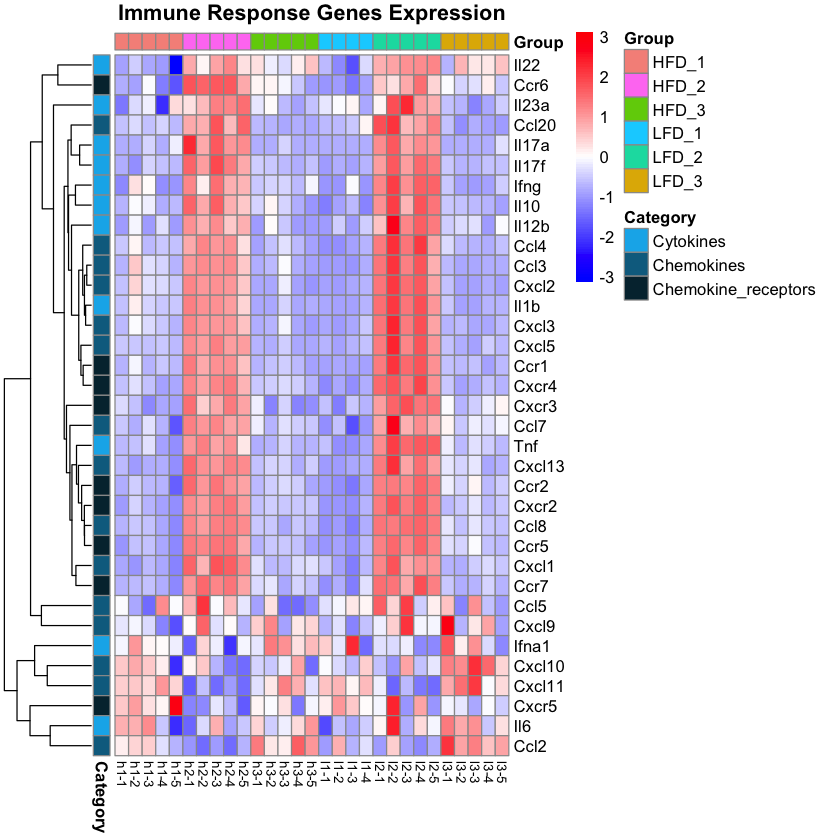

In [10]:
create_gene_of_interest_heatmap <- function(dds, gene_list, gene_annotations = NULL, 
                                           title = "Gene Expression Heatmap", 
                                           filename = NULL) {
  
  # Get normalized counts
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  cat("Available genes in dataset:", nrow(plot_data), "\n")
  cat("Sample of available gene IDs:", head(rownames(plot_data)), "\n")
  
  # Find genes in the dataset (try both gene names and Ensembl IDs)
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    # Try to find by gene name first
    if (!is.null(gene_annotations)) {
      # Look for exact match in external_gene_name
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0) {
        # Check if this gene ID exists in plot_data
        if (gene_match[1] %in% rownames(plot_data)) {
          found_genes <- c(found_genes, gene_match[1])
          gene_mapping[gene_match[1]] <- gene
          next
        }
      }
      
      # Try partial match (case insensitive)
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0) {
        # Check if this gene ID exists in plot_data
        if (gene_match[1] %in% rownames(plot_data)) {
          found_genes <- c(found_genes, gene_match[1])
          gene_mapping[gene_match[1]] <- gene
          next
        }
      }
    }
    
    # Try to find by Ensembl ID if it looks like one
    if (grepl("^ENSMUSG", gene)) {
      if (gene %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene)
        gene_mapping[gene] <- gene
      }
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes\n")
  cat("Missing genes:", setdiff(gene_list, gene_mapping), "\n")
  cat("Found gene IDs:", found_genes, "\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  # Verify all found genes exist in plot_data
  missing_in_plot <- setdiff(found_genes, rownames(plot_data))
  if (length(missing_in_plot) > 0) {
    cat("Warning: Some found genes are not in plot_data:", missing_in_plot, "\n")
    # Remove missing genes
    found_genes <- found_genes[found_genes %in% rownames(plot_data)]
    gene_mapping <- gene_mapping[names(gene_mapping) %in% found_genes]
  }
  
  cat("Final genes to plot:", length(found_genes), "\n")
  
  if (length(found_genes) == 0) {
    cat("No valid genes remaining after filtering\n")
    return(NULL)
  }
  
  # Subset data to found genes
  plot_data_subset <- plot_data[found_genes, ]
  
  # Replace rownames with gene names for readability
  rownames(plot_data_subset) <- gene_mapping[rownames(plot_data_subset)]
  
  # Create annotation for samples
  annotation_col <- data.frame(
    Group = colData(vsd)$group,
    row.names = colnames(plot_data_subset)
  )
  
  # Create row annotation for gene categories - FIXED CASE ISSUES
  gene_categories <- data.frame(
    Category = case_when(
      rownames(plot_data_subset) %in% c("Il1b", "Tnf", "Il6", "Il17a", "Il17f", "Il22", "Ifng", "Il23a", "Il12b", "Ifnb1", "Il10", "Ifna1", "Ifna4") ~ "Cytokines",
      rownames(plot_data_subset) %in% c("Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl7", "Ccl8", "Ccl20", 
                "Cxcl1", "Cxcl2", "Cxcl3", "Cxcl5", "Cxcl9", "Cxcl10", "Cxcl11", "Cxcl13") ~ "Chemokines",
      rownames(plot_data_subset) %in% c("Ccr1", "Ccr2", "Ccr5", "Ccr6", "Ccr7", "Cxcr2", "Cxcr3", "Cxcr4", "Cxcr5") ~ "Chemokine_receptors",
      TRUE ~ "Other"
    ),
    row.names = rownames(plot_data_subset)
  )
  
  # Create color palette for groups
  group_colors <- c("HFD_1" = "#f69289", "HFD_2" = "#ff81f2", "HFD_3" = "#70cf07",
                    "LFD_1" = "#00d1ff", "LFD_2" = "#00dcaf", "LFD_3" = "#e0b400")
  
  # Create annotation colors
  ann_colors <- list(
    Group = group_colors,
    Category = c("Cytokines" = "#0cb3eb", "Chemokines" = "#096d8f", "Chemokine_receptors" = "#032e3d")
  )
  
  # Create heatmap
  p <- pheatmap(plot_data_subset,
                 annotation_col = annotation_col,
                 annotation_row = gene_categories,
                 annotation_colors = ann_colors,
                 scale = "row",
                 show_rownames = TRUE,
                 main = title,
                 fontsize_row = 10,
                 fontsize_col = 8,
                 cluster_rows = TRUE,
                 cluster_cols = FALSE,
                 color = colorRampPalette(c("blue", "white", "red"))(100))
  
  # Save plot if filename provided
  if (!is.null(filename)) {
    ggsave(filename, p, width = 14, height = 12, dpi = 300)
  }
  
  return(list(
    plot = p,
    found_genes = found_genes,
    gene_mapping = gene_mapping,
    plot_data = plot_data_subset
  ))
}
# Define your genes of interest
cytokines <- c("Il1b", "Tnf", "Il6", "Il17a", "Il17f", "Il22", "Ifng", "Il23a", "Il12b", "Ifnb1", "Il10", "Ifna1", "Ifna4")
chemokines <- c("Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl7", "Ccl8", "Ccl20", 
                "Cxcl1", "Cxcl2", "Cxcl3", "Cxcl5", "Cxcl9", "Cxcl10", "Cxcl11", "Cxcl13")
chemokine_receptors <- c("Ccr1", "Ccr2", "Ccr5", "Ccr6", "Ccr7", "Cxcr2", "Cxcr3", "Cxcr4", "Cxcr5")

# All genes of interest
all_genes_of_interest <- c(cytokines, chemokines, chemokine_receptors)

# Create the heatmap
cat("Creating heatmap for genes of interest...\n")
immune_heatmap <- create_gene_of_interest_heatmap(
  dds = results$dds,
  gene_list = all_genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  title = "Immune Response Genes Expression",
  filename = "RNAseq_results/immune_genes_heatmap.png"
)

# Show summary
if (!is.null(immune_heatmap)) {
  cat("Heatmap created successfully!\n")
  cat("Genes found:", length(immune_heatmap$found_genes), "\n")
  cat("Genes missing:", setdiff(all_genes_of_interest, immune_heatmap$gene_mapping), "\n")
  
  # Save the data used for the heatmap
  write.csv(immune_heatmap$plot_data, "RNAseq_results/immune_genes_expression_data.csv")
}

Creating heatmap for genes of interest...
Available genes in dataset: 29590 
Found 29 out of 30 genes
Heatmap created successfully!
Genes found: 29 
Genes missing: Il21 


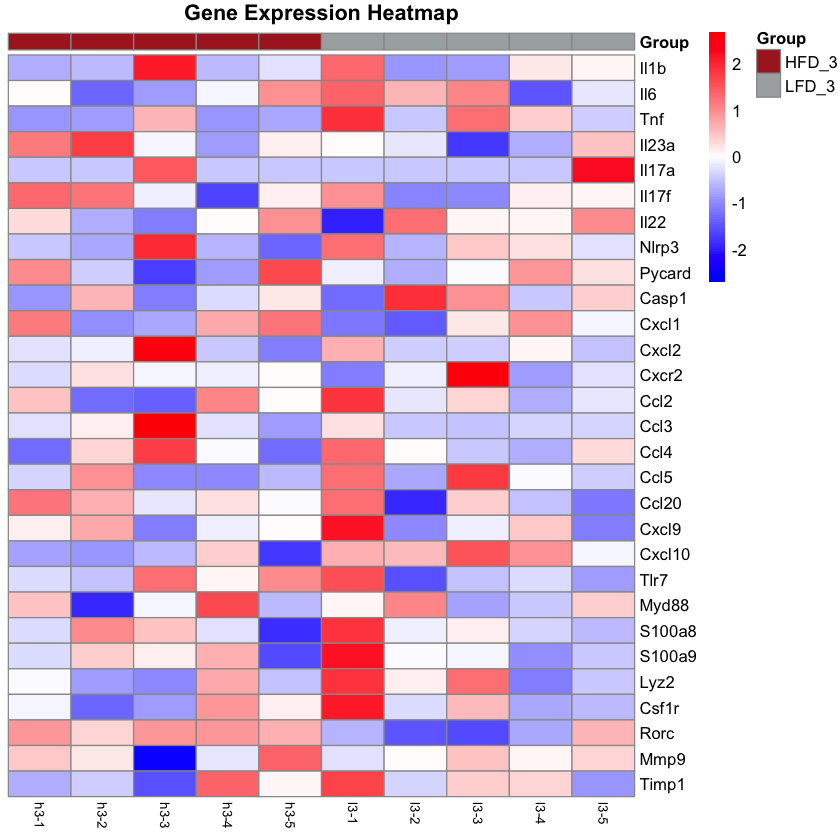

In [11]:
create_gene_of_interest_heatmap <- function(dds, gene_list, gene_annotations = NULL, 
                                           sample_subset = NULL,
                                           title = "Gene Expression Heatmap", 
                                           filename = NULL) {
  
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  if (!is.null(sample_subset)) {
    plot_data <- plot_data[, sample_subset]
  }
  
  cat("Available genes in dataset:", nrow(plot_data), "\n")
  
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    if (!is.null(gene_annotations)) {
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
      
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
    }
    
    if (grepl("^ENSMUSG", gene) && gene %in% rownames(plot_data)) {
      found_genes <- c(found_genes, gene)
      gene_mapping[gene] <- gene
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  plot_data_subset <- plot_data[found_genes, ]
  rownames(plot_data_subset) <- gene_mapping[rownames(plot_data_subset)]
  
  annotation_col <- data.frame(
    Group = colData(vsd)[colnames(plot_data_subset), "group"],
    row.names = colnames(plot_data_subset)
  )
  
  ann_colors <- list(
    Group = c("HFD_3" = "#ab2426", "LFD_3" = "#a9aeae")
  )

  row_labels <- setNames(
  sapply(rownames(plot_data_subset), function(x) bquote(italic(.(x)))),
  rownames(plot_data_subset)
  )
  
  p <- pheatmap(plot_data_subset,
                 annotation_col = annotation_col,
                 annotation_colors = ann_colors,
                 scale = "row",
                 show_rownames = TRUE,
                # display_numbers = TRUE, 

                 main = title,
                 fontsize_row = 10,
                 fontsize_col = 8,
                 fontface_row = "italic",
                 cluster_rows = FALSE,
                 cluster_cols = FALSE,
                 color = colorRampPalette(c("blue", "white", "red"))(100))
  
  if (!is.null(filename)) {
    ggsave(filename, p, width = 6, height = 10, dpi = 300)
  }
  
  return(list(
    plot = p,
    found_genes = found_genes,
    gene_mapping = gene_mapping,
    plot_data = plot_data_subset
  ))
}

genes_of_interest <- c("Il1b", "Il6", "Tnf", "Il23a", "Il17a", "Il17f", "Il22", 
                       "Nlrp3", "Pycard", "Casp1", "Cxcl1", "Cxcl2", "Cxcr2", 
                       "Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl20", "Cxcl9", "Cxcl10", 
                       "Tlr7", "Myd88", "S100a8", "S100a9", "Lyz2", "Csf1r", 
                       "Rorc", "Il21", "Mmp9", "Timp1")

samples_to_include <- colnames(results$dds)[colData(results$dds)$group %in% c("HFD_3", "LFD_3")]

cat("Creating heatmap for genes of interest...\n")
immune_heatmap <- create_gene_of_interest_heatmap(
  dds = results$dds,
  gene_list = genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  sample_subset = samples_to_include,
#   title = "Immune Response Genes Expression (HFD_3 vs LFD_3)",
  filename = "RNAseq_results/immune_genes_heatmap_HFD3_LFD3.svg"
)

if (!is.null(immune_heatmap)) {
  cat("Heatmap created successfully!\n")
  cat("Genes found:", length(immune_heatmap$found_genes), "\n")
  cat("Genes missing:", setdiff(genes_of_interest, immune_heatmap$gene_mapping), "\n")
  
  write.csv(immune_heatmap$plot_data, "RNAseq_results/immune_genes_expression_data_HFD3_LFD3.csv")
}

Extended Data Figure 9a

Creating heatmap for genes of interest...
Available genes in dataset: 29590 
Found 29 out of 30 genes
Heatmap created successfully!
Genes found: 29 
Genes missing: Il21 


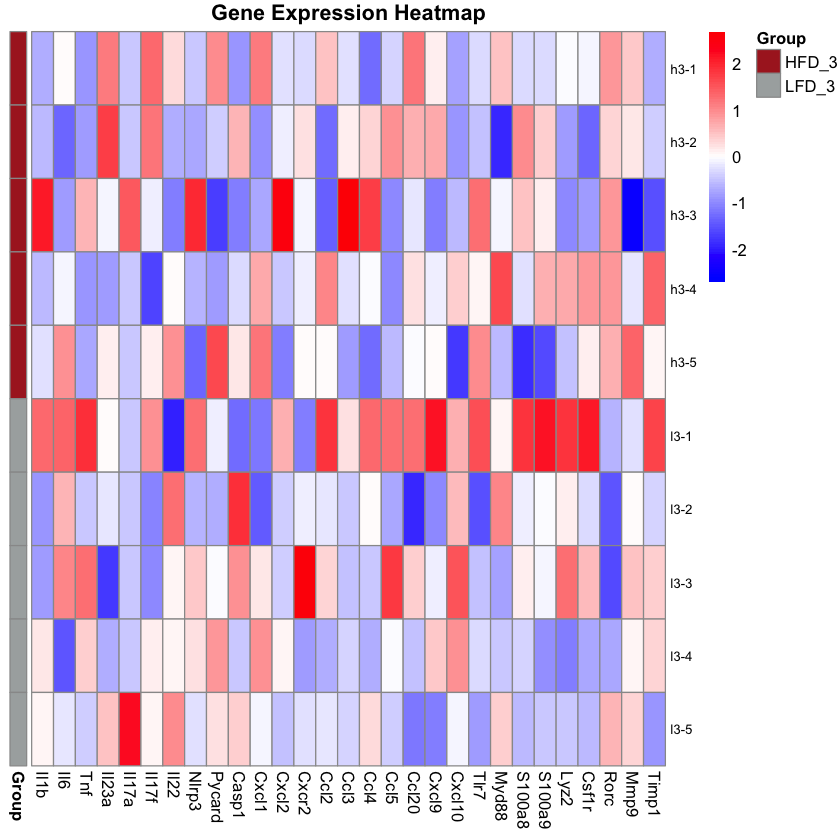

In [12]:
create_gene_of_interest_heatmap <- function(dds, gene_list, gene_annotations = NULL, 
                                           sample_subset = NULL,
                                           title = "Gene Expression Heatmap", 
                                           filename = NULL) {
  
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  if (!is.null(sample_subset)) {
    plot_data <- plot_data[, sample_subset]
  }
  
  cat("Available genes in dataset:", nrow(plot_data), "\n")
  
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    if (!is.null(gene_annotations)) {
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
      
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
    }
    
    if (grepl("^ENSMUSG", gene) && gene %in% rownames(plot_data)) {
      found_genes <- c(found_genes, gene)
      gene_mapping[gene] <- gene
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  plot_data_subset <- plot_data[found_genes, ]
  rownames(plot_data_subset) <- gene_mapping[rownames(plot_data_subset)]
  
  # Transpose the data
  plot_data_transposed <- t(plot_data_subset)
  
  annotation_row <- data.frame(
    Group = colData(vsd)[rownames(plot_data_transposed), "group"],
    row.names = rownames(plot_data_transposed)
  )
  
  ann_colors <- list(
    Group = c("HFD_3" = "#ab2426", "LFD_3" = "#a9aeae")
  )
  
  p <- pheatmap(plot_data_transposed,
                 annotation_row = annotation_row,
                 annotation_colors = ann_colors,
                 scale = "column",
                 show_rownames = TRUE,
                 show_colnames = TRUE,
                 main = title,
                 fontsize_row = 8,
                 fontsize_col = 10,
                 fontface_col = "italic",
                 cluster_rows = FALSE,
                 cluster_cols = FALSE,
                 color = colorRampPalette(c("blue", "white", "red"))(100))
  
  if (!is.null(filename)) {
    ggsave(filename, p, width = 10, height = 6, dpi = 300)
  }
  
  return(list(
    plot = p,
    found_genes = found_genes,
    gene_mapping = gene_mapping,
    plot_data = plot_data_transposed
  ))
}

genes_of_interest <- c("Il1b", "Il6", "Tnf", "Il23a", "Il17a", "Il17f", "Il22", 
                       "Nlrp3", "Pycard", "Casp1", "Cxcl1", "Cxcl2", "Cxcr2", 
                       "Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl20", "Cxcl9", "Cxcl10", 
                       "Tlr7", "Myd88", "S100a8", "S100a9", "Lyz2", "Csf1r", 
                       "Rorc", "Il21", "Mmp9", "Timp1")

samples_to_include <- colnames(results$dds)[colData(results$dds)$group %in% c("HFD_3", "LFD_3")]

cat("Creating heatmap for genes of interest...\n")
immune_heatmap <- create_gene_of_interest_heatmap(
  dds = results$dds,
  gene_list = genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  sample_subset = samples_to_include,
#   title = "Immune Response Genes Expression (HFD_3 vs LFD_3)",
  filename = "RNAseq_results/immune_genes_heatmap_HFD3_LFD3.svg"
)

if (!is.null(immune_heatmap)) {
  cat("Heatmap created successfully!\n")
  cat("Genes found:", length(immune_heatmap$found_genes), "\n")
  cat("Genes missing:", setdiff(genes_of_interest, immune_heatmap$gene_mapping), "\n")
  
  write.csv(immune_heatmap$plot_data, "RNAseq_results/immune_genes_expression_data_HFD3_LFD3.csv")
}

Creating heatmap for genes of interest...
Available genes in dataset: 29590 
Found 29 out of 30 genes
Heatmap created successfully!
Genes found: 29 
Genes missing: Il21 


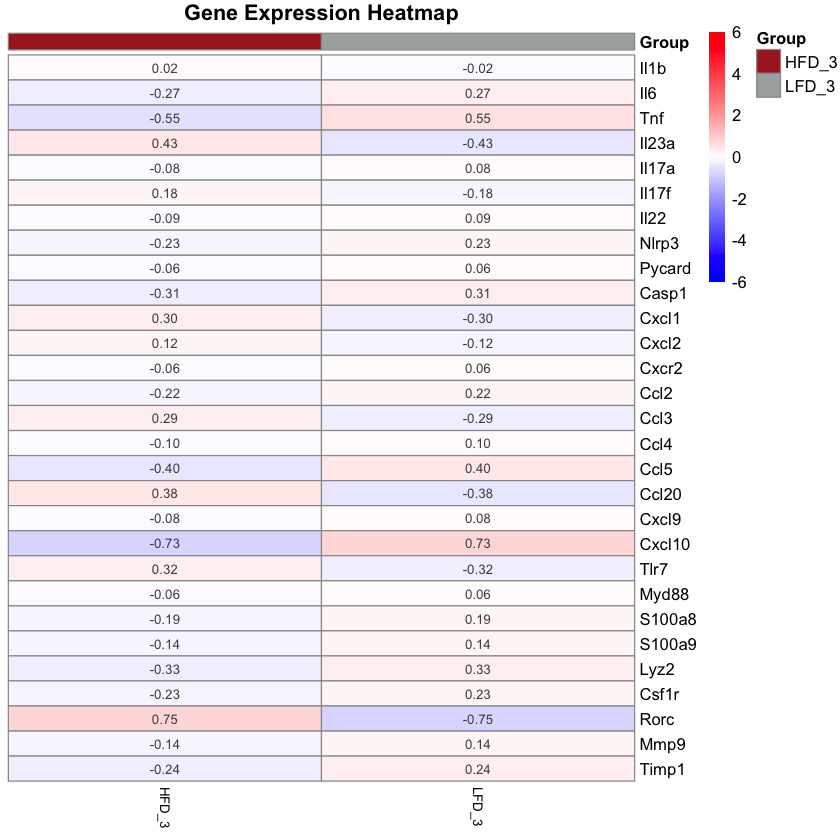

In [13]:
create_gene_of_interest_heatmap <- function(dds, gene_list, gene_annotations = NULL, 
                                           sample_subset = NULL,
                                           title = "Gene Expression Heatmap", 
                                           filename = NULL) {
  
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  if (!is.null(sample_subset)) {
    plot_data <- plot_data[, sample_subset]
  }
  
  cat("Available genes in dataset:", nrow(plot_data), "\n")
  
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    if (!is.null(gene_annotations)) {
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
      
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
    }
    
    if (grepl("^ENSMUSG", gene) && gene %in% rownames(plot_data)) {
      found_genes <- c(found_genes, gene)
      gene_mapping[gene] <- gene
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  plot_data_subset <- plot_data[found_genes, ]
  rownames(plot_data_subset) <- gene_mapping[rownames(plot_data_subset)]
  
  # SCALE FIRST (across all individual samples)
  scaled_data <- t(scale(t(plot_data_subset)))
  
  # THEN calculate group averages on the scaled data
  sample_groups <- colData(vsd)[colnames(scaled_data), "group"]
  avg_data <- t(apply(scaled_data, 1, function(row) {
    tapply(row, sample_groups, mean)
  }))
  
  # Reorder columns to ensure HFD_3, LFD_3 order
  if ("HFD_3" %in% colnames(avg_data) && "LFD_3" %in% colnames(avg_data)) {
    avg_data <- avg_data[, c("HFD_3", "LFD_3")]
  }
  
  annotation_col <- data.frame(
    Group = colnames(avg_data),
    row.names = colnames(avg_data)
  )
  
  ann_colors <- list(
    Group = c("HFD_3" = "#ab2426", "LFD_3" = "#a9aeae")
  )

  row_labels <- setNames(
  sapply(rownames(avg_data), function(x) bquote(italic(.(x)))),
  rownames(avg_data)
  )
  
  p <- pheatmap(avg_data,
                annotation_col = annotation_col,
                annotation_colors = ann_colors,
                scale = "none",
                show_rownames = TRUE,
                display_numbers = TRUE,
                main = title,
                fontsize_row = 10,
                fontsize_col = 8,
                fontface_row = "italic",
                cluster_rows = FALSE,
                cluster_cols = FALSE,
                breaks = seq(-6, 6, length.out = 101),  # Added this line
                color = colorRampPalette(c("blue", "white", "red"))(100))
  
  if (!is.null(filename)) {
    ggsave(filename, p, width = 6, height = 10, dpi = 300)
  }
  
  return(list(
    plot = p,
    found_genes = found_genes,
    gene_mapping = gene_mapping,
    plot_data = avg_data
  ))
}

genes_of_interest <- c("Il1b", "Il6", "Tnf", "Il23a", "Il17a", "Il17f", "Il22", 
                       "Nlrp3", "Pycard", "Casp1", "Cxcl1", "Cxcl2", "Cxcr2", 
                       "Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl20", "Cxcl9", "Cxcl10", 
                       "Tlr7", "Myd88", "S100a8", "S100a9", "Lyz2", "Csf1r", 
                       "Rorc", "Il21", "Mmp9", "Timp1")

samples_to_include <- colnames(results$dds)[colData(results$dds)$group %in% c("HFD_3", "LFD_3")]

cat("Creating heatmap for genes of interest...\n")
immune_heatmap <- create_gene_of_interest_heatmap(
  dds = results$dds,
  gene_list = genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  sample_subset = samples_to_include,
#   title = "Immune Response Genes Expression (HFD_3 vs LFD_3)",
  filename = "RNAseq_results/immune_genes_heatmap_HFD3_LFD3.svg"
)

if (!is.null(immune_heatmap)) {
  cat("Heatmap created successfully!\n")
  cat("Genes found:", length(immune_heatmap$found_genes), "\n")
  cat("Genes missing:", setdiff(genes_of_interest, immune_heatmap$gene_mapping), "\n")
  
  write.csv(immune_heatmap$plot_data, "RNAseq_results/immune_genes_expression_data_HFD3_LFD3.csv")
}

Creating heatmap for genes of interest...
Available genes in dataset: 29590 
Found 29 out of 30 genes
Heatmap created successfully!
Genes found: 29 
Genes missing: Il21 


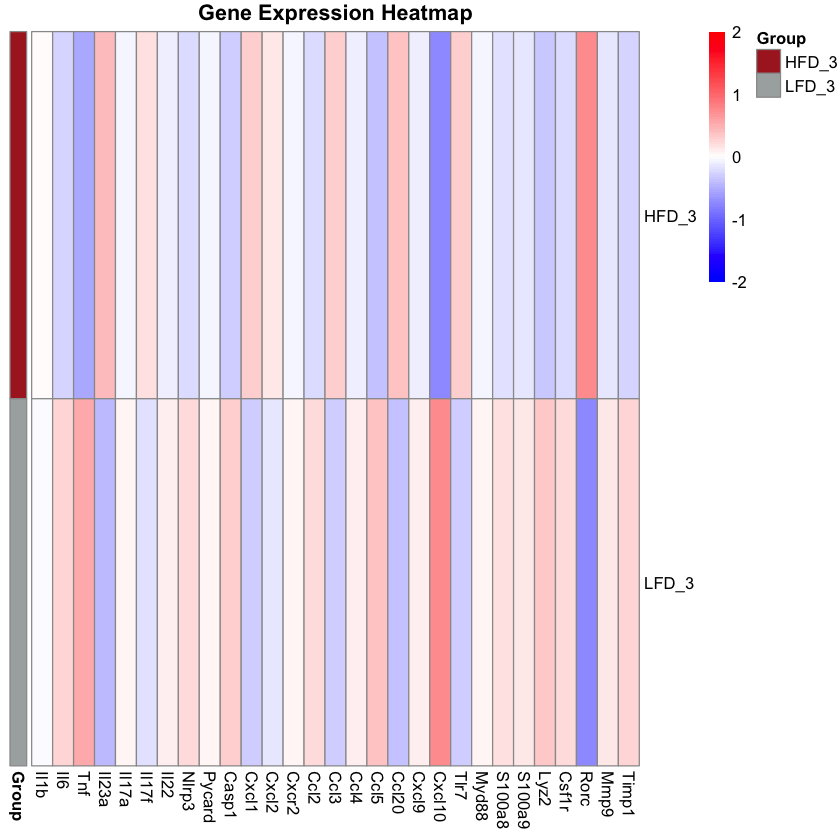

In [14]:
create_gene_of_interest_heatmap <- function(dds, gene_list, gene_annotations = NULL, 
                                           sample_subset = NULL,
                                           title = "Gene Expression Heatmap", 
                                           filename = NULL) {
  
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  if (!is.null(sample_subset)) {
    plot_data <- plot_data[, sample_subset]
  }
  
  cat("Available genes in dataset:", nrow(plot_data), "\n")
  
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    if (!is.null(gene_annotations)) {
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
      
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
    }
    
    if (grepl("^ENSMUSG", gene) && gene %in% rownames(plot_data)) {
      found_genes <- c(found_genes, gene)
      gene_mapping[gene] <- gene
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  plot_data_subset <- plot_data[found_genes, ]
  rownames(plot_data_subset) <- gene_mapping[rownames(plot_data_subset)]
  
  # SCALE FIRST (across all individual samples)
  scaled_data <- t(scale(t(plot_data_subset)))
  
  # THEN calculate group averages on the scaled data
  sample_groups <- colData(vsd)[colnames(scaled_data), "group"]
  avg_data <- t(apply(scaled_data, 1, function(row) {
    tapply(row, sample_groups, mean)
  }))
  
  # Reorder columns to ensure HFD_3, LFD_3 order
  if ("HFD_3" %in% colnames(avg_data) && "LFD_3" %in% colnames(avg_data)) {
    avg_data <- avg_data[, c("HFD_3", "LFD_3")]
  }
  
  # Transpose the data
  avg_data_transposed <- t(avg_data)
  
  annotation_row <- data.frame(
    Group = rownames(avg_data_transposed),
    row.names = rownames(avg_data_transposed)
  )
  
  ann_colors <- list(
    Group = c("HFD_3" = "#ab2426", "LFD_3" = "#a9aeae")
  )
  
  p <- pheatmap(avg_data_transposed,
                annotation_row = annotation_row,
                annotation_colors = ann_colors,
                scale = "none",
                show_rownames = TRUE,
                show_colnames = TRUE,
                # display_numbers = TRUE,
                number_format = "%.2f",
                fontsize_number = 8,
                main = title,
                fontsize_row = 10,
                fontsize_col = 10,
                fontface_col = "italic",
                cluster_rows = FALSE,
                cluster_cols = FALSE,
                breaks = seq(-2, 2, length.out = 101),
                color = colorRampPalette(c("blue", "white", "red"))(100))
  
  if (!is.null(filename)) {
    ggsave(filename, p, width = 10, height = 2, dpi = 300)
  }
  
  return(list(
    plot = p,
    found_genes = found_genes,
    gene_mapping = gene_mapping,
    plot_data = avg_data_transposed
  ))
}

genes_of_interest <- c("Il1b", "Il6", "Tnf", "Il23a", "Il17a", "Il17f", "Il22", 
                       "Nlrp3", "Pycard", "Casp1", "Cxcl1", "Cxcl2", "Cxcr2", 
                       "Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl20", "Cxcl9", "Cxcl10", 
                       "Tlr7", "Myd88", "S100a8", "S100a9", "Lyz2", "Csf1r", 
                       "Rorc", "Il21", "Mmp9", "Timp1")

samples_to_include <- colnames(results$dds)[colData(results$dds)$group %in% c("HFD_3", "LFD_3")]

cat("Creating heatmap for genes of interest...\n")
immune_heatmap <- create_gene_of_interest_heatmap(
  dds = results$dds,
  gene_list = genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  sample_subset = samples_to_include,
#   title = "Immune Response Genes Expression (HFD_3 vs LFD_3)",
  filename = "RNAseq_results/immune_genes_heatmap_HFD3_LFD3.svg"
)

if (!is.null(immune_heatmap)) {
  cat("Heatmap created successfully!\n")
  cat("Genes found:", length(immune_heatmap$found_genes), "\n")
  cat("Genes missing:", setdiff(genes_of_interest, immune_heatmap$gene_mapping), "\n")
  
  write.csv(immune_heatmap$plot_data, "RNAseq_results/immune_genes_expression_data_HFD3_LFD3.csv")
}

Creating PCA plot for HFD_3 and LFD_3 samples...


using ntop=500 top features by variance

Warning message:
“The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”


PCA plot saved to: RNAseq_results/pca_plot_HFD3_LFD3.png 

Variance explained by PC1: 62 %
Variance explained by PC2: 16 %

Euclidean distance between group centroids: 5.9 


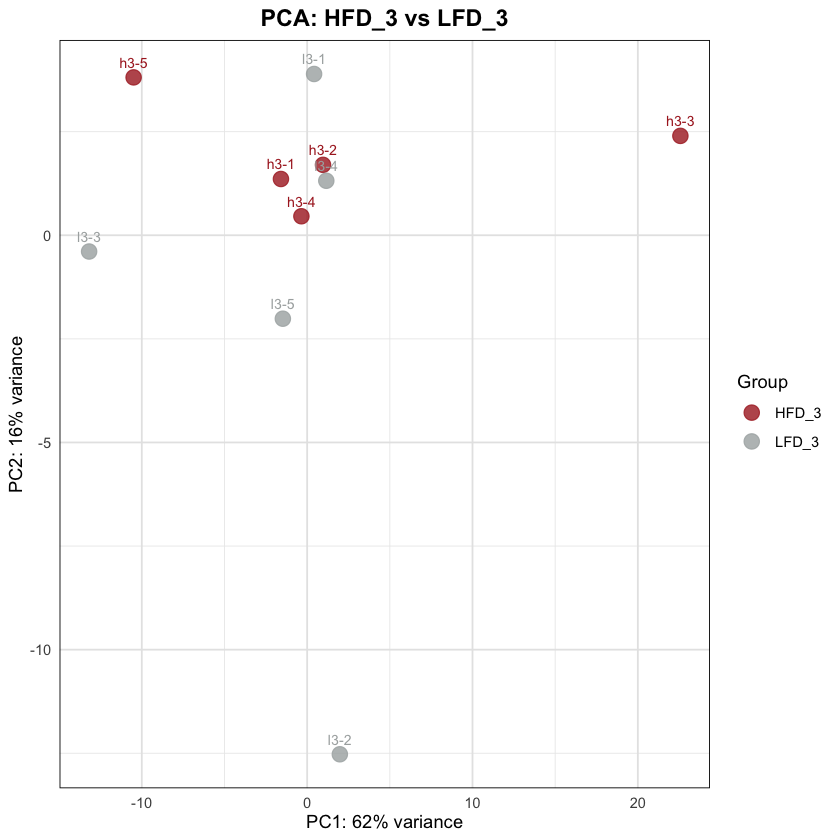

In [15]:
# PCA plot for HFD_3 and LFD_3 samples
library(ggplot2)

create_pca_plot <- function(dds, sample_subset = NULL, title = "PCA Plot", filename = NULL) {
  
  # Get VST-transformed data
  vsd <- vst(dds, blind = FALSE)
  
  # Subset to specific samples if provided
  if (!is.null(sample_subset)) {
    vsd_subset <- vsd[, sample_subset]
  } else {
    vsd_subset <- vsd
  }
  
  # Perform PCA
  pca_data <- plotPCA(vsd_subset, intgroup = "group", returnData = TRUE)
  percent_var <- round(100 * attr(pca_data, "percentVar"))
  
  # Create plot
  p <- ggplot(pca_data, aes(x = PC1, y = PC2, color = group, label = name)) +
    geom_point(size = 4, alpha = 0.8) +
    geom_text(vjust = -1, hjust = 0.5, size = 3, show.legend = FALSE) +
    scale_color_manual(values = c("HFD_3" = "#ab2426", "LFD_3" = "#a9aeae")) +
    labs(
      title = title,
      x = paste0("PC1: ", percent_var[1], "% variance"),
      y = paste0("PC2: ", percent_var[2], "% variance"),
      color = "Group"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
      legend.position = "right",
      panel.grid.major = element_line(color = "gray90"),
      panel.border = element_rect(color = "black", fill = NA, size = 0.5)
    )
  
  if (!is.null(filename)) {
    ggsave(filename, p, width = 8, height = 6, dpi = 300)
    cat("PCA plot saved to:", filename, "\n")
  }
  
  return(list(
    plot = p,
    pca_data = pca_data,
    percent_var = percent_var
  ))
}

# Select HFD_3 and LFD_3 samples
samples_to_include <- colnames(results$dds)[colData(results$dds)$group %in% c("HFD_3", "LFD_3")]

cat("Creating PCA plot for HFD_3 and LFD_3 samples...\n")
pca_result <- create_pca_plot(
  dds = results$dds,
  sample_subset = samples_to_include,
  title = "PCA: HFD_3 vs LFD_3",
  filename = "RNAseq_results/pca_plot_HFD3_LFD3.png"
)

print(pca_result$plot)

# Print variance explained
cat("\nVariance explained by PC1:", pca_result$percent_var[1], "%\n")
cat("Variance explained by PC2:", pca_result$percent_var[2], "%\n")

# Calculate distance between groups
pca_data <- pca_result$pca_data
hfd3_samples <- pca_data[pca_data$group == "HFD_3", ]
lfd3_samples <- pca_data[pca_data$group == "LFD_3", ]

hfd3_centroid <- c(mean(hfd3_samples$PC1), mean(hfd3_samples$PC2))
lfd3_centroid <- c(mean(lfd3_samples$PC1), mean(lfd3_samples$PC2))
distance <- sqrt(sum((hfd3_centroid - lfd3_centroid)^2))

cat("\nEuclidean distance between group centroids:", round(distance, 2), "\n")

Second plot: Extended Data Figure 9b

Creating PCA plot for all samples (genes of interest only)...
Found 29 out of 30 genes for PCA
PCA plot saved to: RNAseq_results/pca_plot_all_samples_immune_genes.png 

Variance explained by PC1: 72.5 %
Variance explained by PC2: 9.5 %

Creating PCA plot for HFD_3 vs LFD_3 (genes of interest only)...
Found 29 out of 30 genes for PCA
PCA plot saved to: RNAseq_results/pca_plot_HFD3_LFD3_immune_genes.svg 


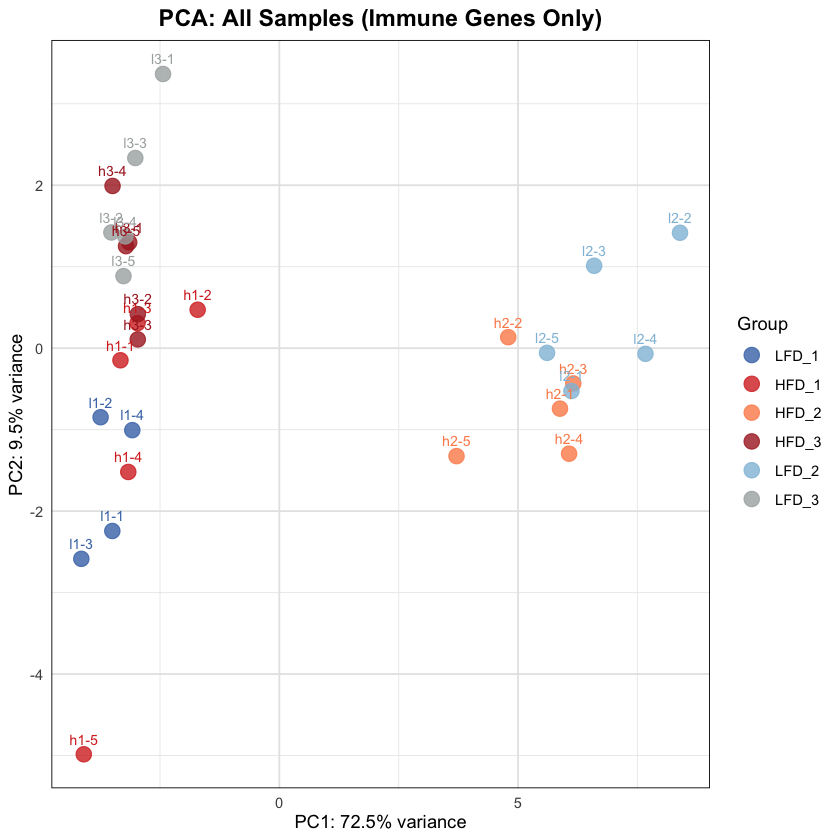


Variance explained by PC1: 30.7 %
Variance explained by PC2: 24.3 %


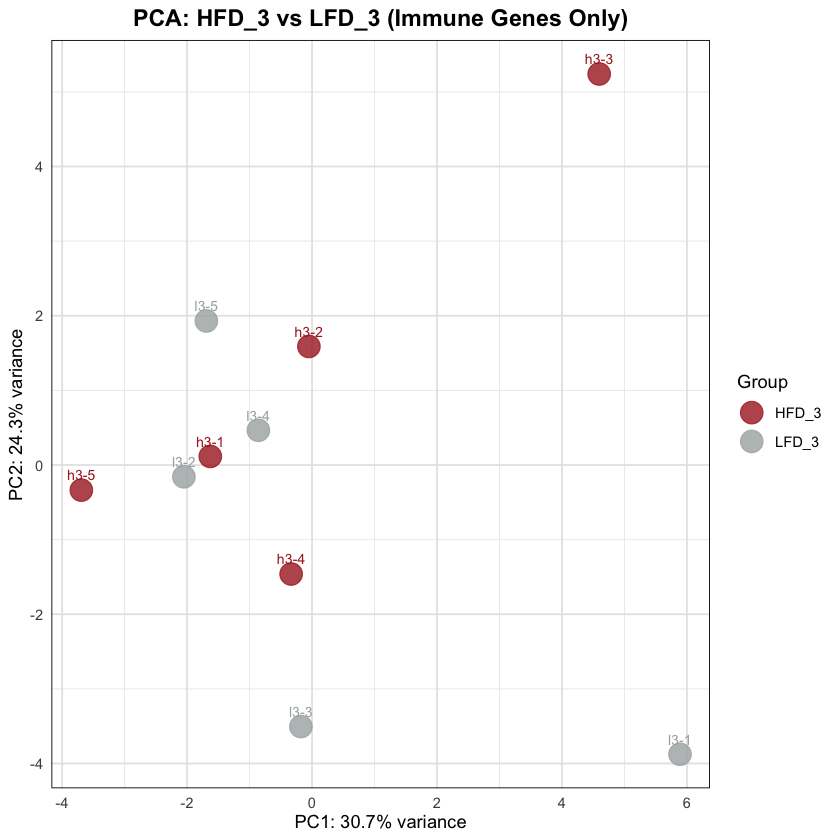

In [16]:
create_pca_plot_genes_of_interest <- function(dds, gene_list, gene_annotations = NULL, 
                                               sample_subset = NULL, 
                                               title = "PCA Plot", filename = NULL,
                                               point_size = 4) {  # ADD THIS PARAMETER
  
  # Get VST-transformed data
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  # Subset to specific samples if provided
  if (!is.null(sample_subset)) {
    plot_data <- plot_data[, sample_subset]
    vsd_subset <- vsd[, sample_subset]
  } else {
    vsd_subset <- vsd
  }
  
  # Find genes of interest
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    if (!is.null(gene_annotations)) {
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
      
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes for PCA\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  # Subset to genes of interest
  plot_data_subset <- plot_data[found_genes, ]
  
  # Perform PCA manually
  pca_result <- prcomp(t(plot_data_subset), scale. = TRUE, center = TRUE)
  
  # Calculate variance explained
  percent_var <- round(100 * pca_result$sdev^2 / sum(pca_result$sdev^2), 1)
  
  # Create data frame for plotting
  pca_data <- data.frame(
    PC1 = pca_result$x[, 1],
    PC2 = pca_result$x[, 2],
    name = colnames(plot_data_subset),
    group = colData(vsd_subset)$group
  )
  
  # Create plot
  p <- ggplot(pca_data, aes(x = PC1, y = PC2, color = group, label = name)) +
    geom_point(size = point_size, alpha = 0.8) +  # USE THE PARAMETER
    geom_text(vjust = -1, hjust = 0.5, size = 3, show.legend = FALSE) +
    scale_color_manual(values = c(
      "HFD_1" = "#d73027", 
      "HFD_2" = "#fc8d59", 
      "HFD_3" = "#ab2426",
      "LFD_1" = "#4575b4", 
      "LFD_2" = "#91bfdb", 
      "LFD_3" = "#a9aeae"
    )) +
    labs(
      title = title,
      x = paste0("PC1: ", percent_var[1], "% variance"),
      y = paste0("PC2: ", percent_var[2], "% variance"),
      color = "Group"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
      legend.position = "right",
      panel.grid.major = element_line(color = "gray90"),
      panel.border = element_rect(color = "black", fill = NA, size = 0.5)
    )
  
  if (!is.null(filename)) {
    ggsave(filename, p, width = 10, height = 8, dpi = 300)
    cat("PCA plot saved to:", filename, "\n")
  }
  
  return(list(
    plot = p,
    pca_data = pca_data,
    pca_result = pca_result,
    percent_var = percent_var,
    genes_used = found_genes
  ))
}

genes_of_interest <- c("Il1b", "Il6", "Tnf", "Il23a", "Il17a", "Il17f", "Il22", 
                       "Nlrp3", "Pycard", "Casp1", "Cxcl1", "Cxcl2", "Cxcr2", 
                       "Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl20", "Cxcl9", "Cxcl10", 
                       "Tlr7", "Myd88", "S100a8", "S100a9", "Lyz2", "Csf1r", 
                       "Rorc", "Il21", "Mmp9", "Timp1")

# PCA with all samples, genes of interest only
cat("Creating PCA plot for all samples (genes of interest only)...\n")
pca_genes_all <- create_pca_plot_genes_of_interest(
  dds = results$dds,
  gene_list = genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  sample_subset = NULL,
  title = "PCA: All Samples (Immune Genes Only)",
  filename = "RNAseq_results/pca_plot_all_samples_immune_genes.png"
)

print(pca_genes_all$plot)
cat("\nVariance explained by PC1:", pca_genes_all$percent_var[1], "%\n")
cat("Variance explained by PC2:", pca_genes_all$percent_var[2], "%\n")

# PCA with HFD_3 and LFD_3 only, genes of interest only
samples_to_include <- colnames(results$dds)[colData(results$dds)$group %in% c("HFD_3", "LFD_3")]

cat("\nCreating PCA plot for HFD_3 vs LFD_3 (genes of interest only)...\n")
pca_genes_hfd3_lfd3 <- create_pca_plot_genes_of_interest(
  dds = results$dds,
  gene_list = genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  sample_subset = samples_to_include,
  title = "PCA: HFD_3 vs LFD_3 (Immune Genes Only)",
  filename = "RNAseq_results/pca_plot_HFD3_LFD3_immune_genes.svg",
  point_size = 6
)

print(pca_genes_hfd3_lfd3$plot)
cat("\nVariance explained by PC1:", pca_genes_hfd3_lfd3$percent_var[1], "%\n")
cat("Variance explained by PC2:", pca_genes_hfd3_lfd3$percent_var[2], "%\n")

Found genes: 86  Missing genes: 8 
Done. Missing genes: Csf2, Pla2g43, Pla2g2a, Alox15b, Cxcl7, Cxcl8, Nox2, Nrf2 


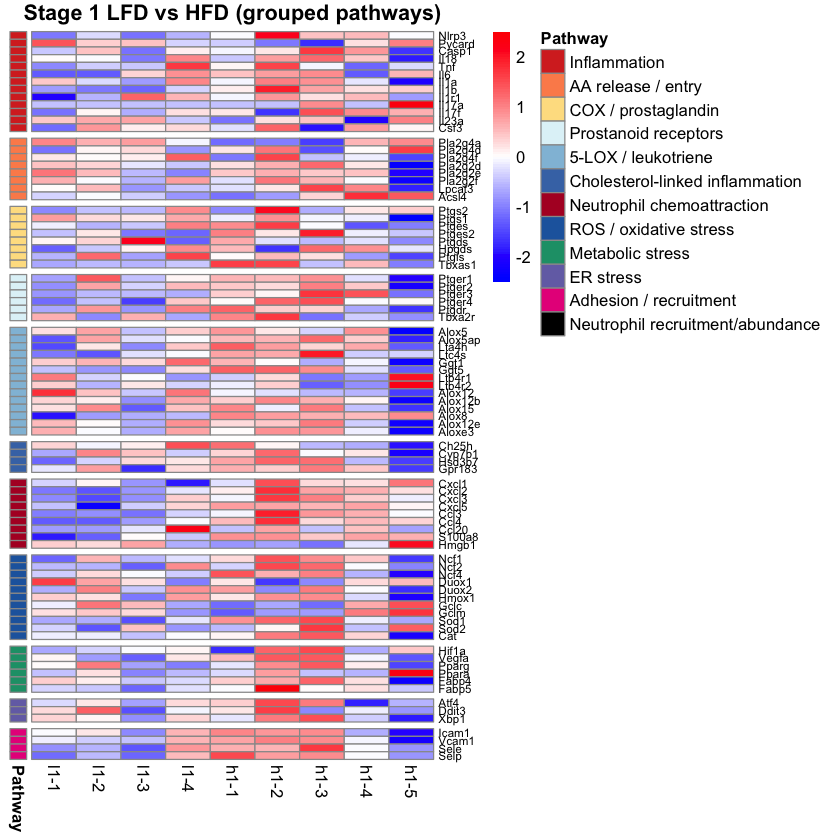

In [17]:
genes_stage1 <- c(
  "Nlrp3","Pycard","Casp1","Il18","Tnf","Il6","Il1a","Il1b","Il1r1","Il17a","Il17f","Il23a","Csf3","Csf2",
  "Pla2g4a","Pla2g4d","Pla2g43","Pla2g4f","Pla2g2a","Pla2g2d","Pla2g2e","Pla2g2f","Lpcat3","Acsl4",
  "Ptgs2","Ptgs1","Ptges","Ptges2","Ptgds","Hpgds","Ptgis","Tbxas1",
  "Ptger1","Ptger2","Ptger3","Ptger4","Ptgdr","Tbxa2r",
  "Alox5","Alox5ap","Lta4h","Ltc4s","Ggt1","Ggt5","Ltb4r1","Ltb4r2","Alox12","Alox12b","Alox15","Alox15b","Alox8","Alox12e","Aloxe3",
  "Ch25h","Cyp7b1","Hsd3b7","Gpr183",
  "Cxcl1","Cxcl2","Cxcl3","Cxcl5","Cxcl7", "Cxcl8","Ccl3","Ccl4","Ccl20","S100a8","Hmgb1",
  "Nox2","Ncf1","Ncf2","Ncf4","Duox1","Duox2","Hmox1","Nrf2","Gclc","Gclm","Sod1","Sod2","Cat",
  "Hif1a","Vegfa","Pparg","Ppara","Fabp4","Fabp5",
  "Atf4","Ddit3","Xbp1",
  "Icam1","Vcam1","Sele","Selp"
)

# --- robust gene/sample matching before pheatmap ---
dds_mat <- counts(results$dds, normalized = TRUE)
dds_rows <- rownames(dds_mat)

sample_subset <- c("l1-1","l1-2","l1-3", "l1-4", "l1-5", "h1-1","h1-2","h1-3", "h1-4", "h1-5")
sample_subset <- intersect(sample_subset, colnames(dds_mat))
if (length(sample_subset) == 0) stop("None of the requested samples are in results$dds")

ann <- results$count_matrix_annotated
ann$external_gene_name_upper <- toupper(ann$external_gene_name)

map_one_gene <- function(g) {
  gu <- toupper(g)

  # 1) direct rowname match (if symbols are rownames)
  if (gu %in% toupper(dds_rows)) return(dds_rows[match(gu, toupper(dds_rows))])

  # 2) annotation match by symbol -> try gene_id
  hits <- ann[ann$external_gene_name_upper == gu, , drop = FALSE]
  for (candidate_col in c("gene_id", "gene_id_clean")) {
    if (candidate_col %in% colnames(hits)) {
      vals <- unique(na.omit(as.character(hits[[candidate_col]])))
      vals <- vals[vals %in% dds_rows]
      if (length(vals) > 0) return(vals[1])
    }
  }

  return(NA_character_)
}

gene_ids <- vapply(genes_stage1, map_one_gene, character(1))
found <- !is.na(gene_ids)
missing_genes <- genes_stage1[!found]

mat <- dds_mat[gene_ids[found], sample_subset, drop = FALSE]
rownames(mat) <- genes_stage1[found]

cat("Found genes:", nrow(mat), " Missing genes:", length(missing_genes), "\n")
if (nrow(mat) == 0) stop("No requested genes matched rows in results$dds.")
if (ncol(mat) == 0) stop("No requested samples matched columns in results$dds.")

log_mat <- log2(mat + 1)
z_mat <- t(scale(t(log_mat)))
z_mat[is.na(z_mat)] <- 0


dir.create("RNAseq_results", showWarnings = FALSE, recursive = TRUE)


# Group genes for row annotation + separators
gene_groups <- list(
  "Inflammation" = c("Nlrp3","Pycard","Casp1","Il18","Tnf","Il6","Il1a","Il1b","Il1r1","Il17a","Il17f","Il23a","Csf3","Csf2"),
  "AA release / entry" = c("Pla2g4a","Pla2g4d","Pla2g43","Pla2g4f","Pla2g2a","Pla2g2d","Pla2g2e","Pla2g2f","Lpcat3","Acsl4"),
  "COX / prostaglandin" = c("Ptgs2","Ptgs1","Ptges","Ptges2","Ptgds","Hpgds","Ptgis","Tbxas1"),
  "Prostanoid receptors" = c("Ptger1","Ptger2","Ptger3","Ptger4","Ptgdr","Tbxa2r"),
  "5-LOX / leukotriene" = c("Alox5","Alox5ap","Lta4h","Ltc4s","Ggt1","Ggt5","Ltb4r1","Ltb4r2","Alox12","Alox12b","Alox15","Alox15b","Alox8","Alox12e","Aloxe3"),
  "Cholesterol-linked inflammation" = c("Ch25h","Cyp7b1","Hsd3b7","Gpr183"),
  "Neutrophil chemoattraction" = c("Cxcl1","Cxcl2","Cxcl3","Cxcl5","Cxcl7", "Cxcl8", "Ccl3","Ccl4","Ccl20","S100a8","Hmgb1"),
  "ROS / oxidative stress" = c("Nox2","Ncf1","Ncf2","Ncf4","Duox1","Duox2","Hmox1","Nrf2","Gclc","Gclm","Sod1","Sod2","Cat"),
  "Metabolic stress" = c("Hif1a","Vegfa","Pparg","Ppara","Fabp4","Fabp5"),
  "ER stress" = c("Atf4","Ddit3","Xbp1"),
  "Adhesion / recruitment" = c("Icam1","Vcam1","Sele","Selp")
)

# Map each gene to its group
gene_to_group <- unlist(lapply(names(gene_groups), function(g) setNames(rep(g, length(gene_groups[[g]])), gene_groups[[g]])))

# Keep only genes present in z_mat, and order by pathway then original list order within pathway
present_genes <- rownames(z_mat)
group_df <- data.frame(
  gene = present_genes,
  pathway = gene_to_group[present_genes],
  stringsAsFactors = FALSE
)
group_df <- group_df[!is.na(group_df$pathway), ]
group_df$pathway <- factor(group_df$pathway, levels = names(gene_groups))
group_df <- group_df[order(group_df$pathway), , drop = FALSE]

z_mat_ordered <- z_mat[group_df$gene, , drop = FALSE]

annotation_row <- data.frame(Pathway = group_df$pathway)
rownames(annotation_row) <- group_df$gene

# row separators between groups
group_sizes <- table(group_df$pathway)
gaps_row <- cumsum(as.numeric(group_sizes))
gaps_row <- gaps_row[-length(gaps_row)]

ann_colors <- list(
  Pathway = c(
    "Inflammation" = "#d73027",
    "AA release / entry" = "#fc8d59",
    "COX / prostaglandin" = "#fee090",
    "Prostanoid receptors" = "#e0f3f8",
    "5-LOX / leukotriene" = "#91bfdb",
    "Cholesterol-linked inflammation" = "#4575b4",
    "Neutrophil chemoattraction" = "#b2182b",
    "ROS / oxidative stress" = "#2166ac",
    "Metabolic stress" = "#1b9e77",
    "ER stress" = "#7570b3",
    "Adhesion / recruitment" = "#e7298a",
    "Neutrophil recruitment/abundance" = "black"
  )
)

p <- pheatmap::pheatmap(
  z_mat_ordered,
  annotation_row = annotation_row,
  annotation_colors = ann_colors,
  gaps_row = gaps_row,
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  scale = "none",
  color = colorRampPalette(c("blue", "white", "red"))(100),
  breaks = seq(-2.5, 2.5, length.out = 101),
  main = "Stage 1 LFD vs HFD (grouped pathways)",
  fontsize_row = 7,
  fontsize_col = 10,
  fontface_row = "italic"
)


ggplot2::ggsave("RNAseq_results/stage1_hfd1_vs_lfd1_custom_genes_heatmap.png", p$gtable, width = 10, height = 20, dpi = 300)
ggplot2::ggsave("RNAseq_results/stage1_hfd1_vs_lfd1_custom_genes_heatmap.svg", p$gtable, width = 10, height = 20)

write.csv(z_mat, "RNAseq_results/stage1_hfd1_vs_lfd1_custom_genes_log2cpm_zscore.csv")
writeLines(
  c(
    paste0("Total requested genes: ", length(genes_stage1)),
    paste0("Found in matrix: ", sum(found)),
    paste0("Missing from matrix: ", length(missing_genes)),
    "",
    "Missing genes:",
    if (length(missing_genes)) paste0("- ", missing_genes) else "- None"
  ),
  "RNAseq_results/stage1_hfd1_vs_lfd1_custom_genes_report.txt"
)

cat("Done. Missing genes:", if (length(missing_genes)) paste(missing_genes, collapse = ", ") else "None", "\n")


Found genes: 86  Missing genes: 8 
Done. Missing genes: Csf2, Pla2g43, Pla2g2a, Alox15b, Cxcl7, Cxcl8, Nox2, Nrf2 


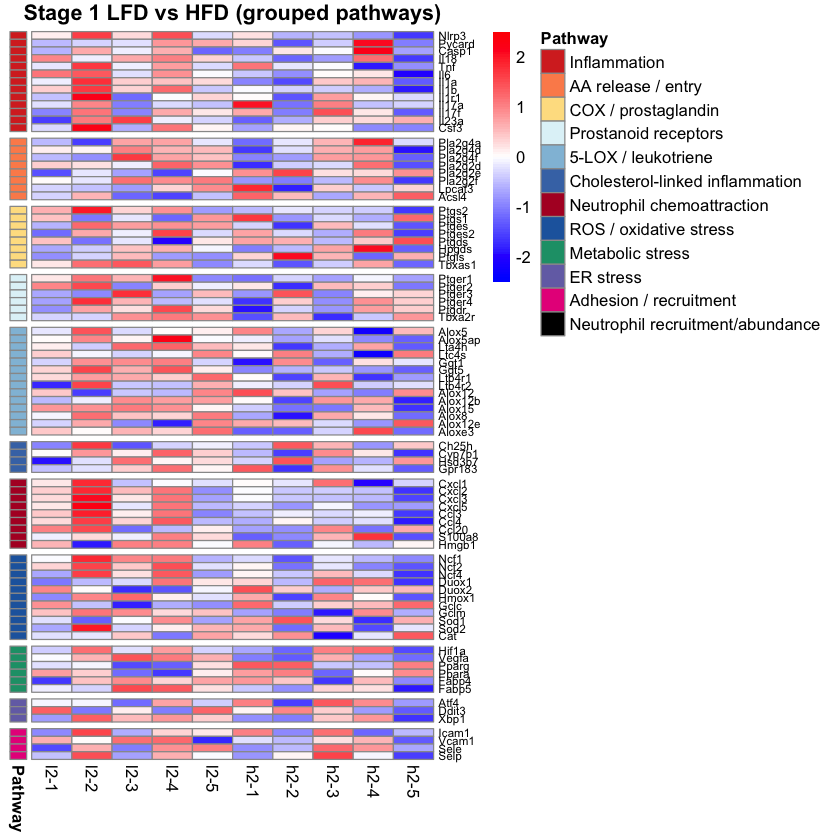

In [18]:
genes_stage1 <- c(
  "Nlrp3","Pycard","Casp1","Il18","Tnf","Il6","Il1a","Il1b","Il1r1","Il17a","Il17f","Il23a","Csf3","Csf2",
  "Pla2g4a","Pla2g4d","Pla2g43","Pla2g4f","Pla2g2a","Pla2g2d","Pla2g2e","Pla2g2f","Lpcat3","Acsl4",
  "Ptgs2","Ptgs1","Ptges","Ptges2","Ptgds","Hpgds","Ptgis","Tbxas1",
  "Ptger1","Ptger2","Ptger3","Ptger4","Ptgdr","Tbxa2r",
  "Alox5","Alox5ap","Lta4h","Ltc4s","Ggt1","Ggt5","Ltb4r1","Ltb4r2","Alox12","Alox12b","Alox15","Alox15b","Alox8","Alox12e","Aloxe3",
  "Ch25h","Cyp7b1","Hsd3b7","Gpr183",
  "Cxcl1","Cxcl2","Cxcl3","Cxcl5","Cxcl7", "Cxcl8","Ccl3","Ccl4","Ccl20","S100a8","Hmgb1",
  "Nox2","Ncf1","Ncf2","Ncf4","Duox1","Duox2","Hmox1","Nrf2","Gclc","Gclm","Sod1","Sod2","Cat",
  "Hif1a","Vegfa","Pparg","Ppara","Fabp4","Fabp5",
  "Atf4","Ddit3","Xbp1",
  "Icam1","Vcam1","Sele","Selp"
)

# --- robust gene/sample matching before pheatmap ---
dds_mat <- counts(results$dds, normalized = TRUE)
dds_rows <- rownames(dds_mat)

sample_subset <- c("l2-1","l2-2","l2-3", "l2-4", "l2-5", "h2-1","h2-2","h2-3", "h2-4", "h2-5")
sample_subset <- intersect(sample_subset, colnames(dds_mat))
if (length(sample_subset) == 0) stop("None of the requested samples are in results$dds")

ann <- results$count_matrix_annotated
ann$external_gene_name_upper <- toupper(ann$external_gene_name)

map_one_gene <- function(g) {
  gu <- toupper(g)

  # 1) direct rowname match (if symbols are rownames)
  if (gu %in% toupper(dds_rows)) return(dds_rows[match(gu, toupper(dds_rows))])

  # 2) annotation match by symbol -> try gene_id
  hits <- ann[ann$external_gene_name_upper == gu, , drop = FALSE]
  for (candidate_col in c("gene_id", "gene_id_clean")) {
    if (candidate_col %in% colnames(hits)) {
      vals <- unique(na.omit(as.character(hits[[candidate_col]])))
      vals <- vals[vals %in% dds_rows]
      if (length(vals) > 0) return(vals[1])
    }
  }

  return(NA_character_)
}

gene_ids <- vapply(genes_stage1, map_one_gene, character(1))
found <- !is.na(gene_ids)
missing_genes <- genes_stage1[!found]

mat <- dds_mat[gene_ids[found], sample_subset, drop = FALSE]
rownames(mat) <- genes_stage1[found]

cat("Found genes:", nrow(mat), " Missing genes:", length(missing_genes), "\n")
if (nrow(mat) == 0) stop("No requested genes matched rows in results$dds.")
if (ncol(mat) == 0) stop("No requested samples matched columns in results$dds.")

log_mat <- log2(mat + 1)
z_mat <- t(scale(t(log_mat)))
z_mat[is.na(z_mat)] <- 0


dir.create("RNAseq_results", showWarnings = FALSE, recursive = TRUE)


# Group genes for row annotation + separators
gene_groups <- list(
  "Inflammation" = c("Nlrp3","Pycard","Casp1","Il18","Tnf","Il6","Il1a","Il1b","Il1r1","Il17a","Il17f","Il23a","Csf3","Csf2"),
  "AA release / entry" = c("Pla2g4a","Pla2g4d","Pla2g43","Pla2g4f","Pla2g2a","Pla2g2d","Pla2g2e","Pla2g2f","Lpcat3","Acsl4"),
  "COX / prostaglandin" = c("Ptgs2","Ptgs1","Ptges","Ptges2","Ptgds","Hpgds","Ptgis","Tbxas1"),
  "Prostanoid receptors" = c("Ptger1","Ptger2","Ptger3","Ptger4","Ptgdr","Tbxa2r"),
  "5-LOX / leukotriene" = c("Alox5","Alox5ap","Lta4h","Ltc4s","Ggt1","Ggt5","Ltb4r1","Ltb4r2","Alox12","Alox12b","Alox15","Alox15b","Alox8","Alox12e","Aloxe3"),
  "Cholesterol-linked inflammation" = c("Ch25h","Cyp7b1","Hsd3b7","Gpr183"),
  "Neutrophil chemoattraction" = c("Cxcl1","Cxcl2","Cxcl3","Cxcl5","Cxcl7", "Cxcl8", "Ccl3","Ccl4","Ccl20","S100a8","Hmgb1"),
  "ROS / oxidative stress" = c("Nox2","Ncf1","Ncf2","Ncf4","Duox1","Duox2","Hmox1","Nrf2","Gclc","Gclm","Sod1","Sod2","Cat"),
  "Metabolic stress" = c("Hif1a","Vegfa","Pparg","Ppara","Fabp4","Fabp5"),
  "ER stress" = c("Atf4","Ddit3","Xbp1"),
  "Adhesion / recruitment" = c("Icam1","Vcam1","Sele","Selp")
)

# Map each gene to its group
gene_to_group <- unlist(lapply(names(gene_groups), function(g) setNames(rep(g, length(gene_groups[[g]])), gene_groups[[g]])))

# Keep only genes present in z_mat, and order by pathway then original list order within pathway
present_genes <- rownames(z_mat)
group_df <- data.frame(
  gene = present_genes,
  pathway = gene_to_group[present_genes],
  stringsAsFactors = FALSE
)
group_df <- group_df[!is.na(group_df$pathway), ]
group_df$pathway <- factor(group_df$pathway, levels = names(gene_groups))
group_df <- group_df[order(group_df$pathway), , drop = FALSE]

z_mat_ordered <- z_mat[group_df$gene, , drop = FALSE]

annotation_row <- data.frame(Pathway = group_df$pathway)
rownames(annotation_row) <- group_df$gene

# row separators between groups
group_sizes <- table(group_df$pathway)
gaps_row <- cumsum(as.numeric(group_sizes))
gaps_row <- gaps_row[-length(gaps_row)]

ann_colors <- list(
  Pathway = c(
    "Inflammation" = "#d73027",
    "AA release / entry" = "#fc8d59",
    "COX / prostaglandin" = "#fee090",
    "Prostanoid receptors" = "#e0f3f8",
    "5-LOX / leukotriene" = "#91bfdb",
    "Cholesterol-linked inflammation" = "#4575b4",
    "Neutrophil chemoattraction" = "#b2182b",
    "ROS / oxidative stress" = "#2166ac",
    "Metabolic stress" = "#1b9e77",
    "ER stress" = "#7570b3",
    "Adhesion / recruitment" = "#e7298a",
    "Neutrophil recruitment/abundance" = "black"
  )
)

p <- pheatmap::pheatmap(
  z_mat_ordered,
  annotation_row = annotation_row,
  annotation_colors = ann_colors,
  gaps_row = gaps_row,
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  scale = "none",
  color = colorRampPalette(c("blue", "white", "red"))(100),
  breaks = seq(-2.5, 2.5, length.out = 101),
  main = "Stage 1 LFD vs HFD (grouped pathways)",
  fontsize_row = 7,
  fontsize_col = 10,
  fontface_row = "italic"
)


ggplot2::ggsave("RNAseq_results/stage2_hfd_vs_lfd_custom_genes_heatmap.png", p$gtable, width = 10, height = 20, dpi = 300)
ggplot2::ggsave("RNAseq_results/stage2_hfd_vs_lfd_custom_genes_heatmap.svg", p$gtable, width = 10, height = 20)

write.csv(z_mat, "RNAseq_results/stage2_hfd_vs_lfd_custom_genes_log2cpm_zscore.csv")
writeLines(
  c(
    paste0("Total requested genes: ", length(genes_stage1)),
    paste0("Found in matrix: ", sum(found)),
    paste0("Missing from matrix: ", length(missing_genes)),
    "",
    "Missing genes:",
    if (length(missing_genes)) paste0("- ", missing_genes) else "- None"
  ),
  "RNAseq_results/stage2_hfd_vs_lfd_custom_genes_report.txt"
)

cat("Done. Missing genes:", if (length(missing_genes)) paste(missing_genes, collapse = ", ") else "None", "\n")


In [19]:
neutrophil_genes <- c("Cxcl1",
"Cxcl2",
"Cxcl3",
"Cxcl5",
"Cxcl12",
"Cxcr2",
"Cxcr4",
"Ccr1",
"Ccr5",
"Itgam",
"Itgb2",
"Sell",
"Selplg",
"Lcn2",
"S100a8",
"S100a9",
"Mpo",
"Elane",
"Ly6g")

neutrophil_groups <- list(
  "Neutrophil recruitment/abundance" = neutrophil_genes
)


Found genes: 18  Missing genes: 1 
Done. Missing genes: Elane 


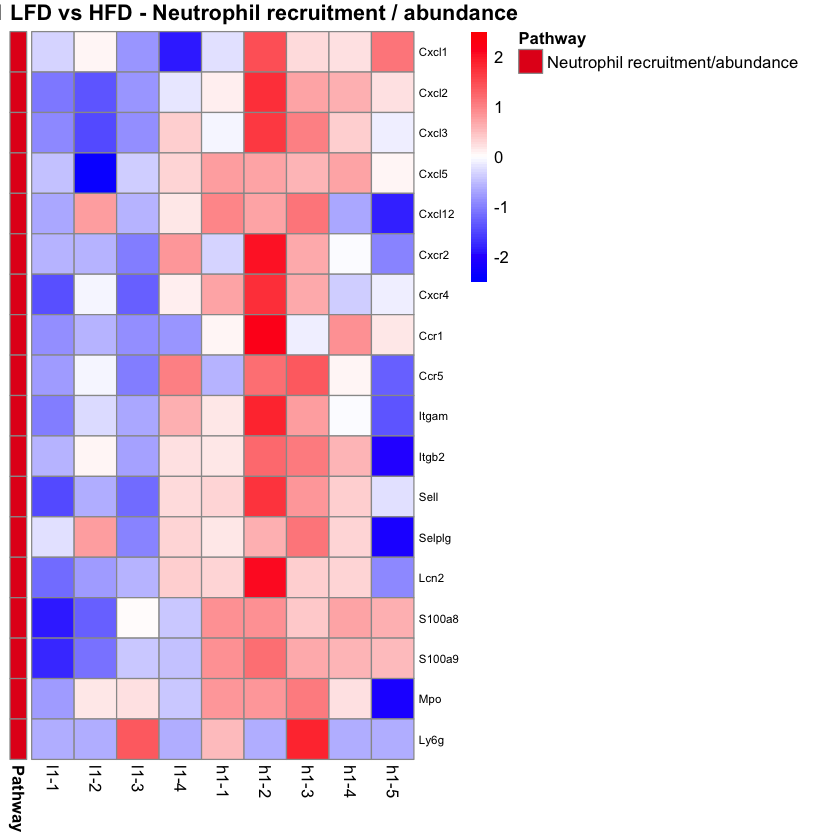

In [20]:
# --- robust gene/sample matching ---
dds_mat  <- counts(results$dds, normalized = TRUE)
dds_rows <- rownames(dds_mat)

sample_subset <- c("l1-1","l1-2","l1-3","l1-4","l1-5",
                   "h1-1","h1-2","h1-3","h1-4","h1-5")
sample_subset <- intersect(sample_subset, colnames(dds_mat))
if (length(sample_subset) == 0) stop("None of the requested samples are in results$dds")

ann <- results$count_matrix_annotated
ann$external_gene_name_upper <- toupper(ann$external_gene_name)

map_one_gene <- function(g) {
  gu <- toupper(g)
  if (gu %in% toupper(dds_rows)) return(dds_rows[match(gu, toupper(dds_rows))])
  hits <- ann[!is.na(ann$external_gene_name_upper) &
              ann$external_gene_name_upper == gu, , drop = FALSE]
  for (col in c("gene_id", "gene_id_clean")) {
    if (col %in% colnames(hits)) {
      vals <- unique(na.omit(as.character(hits[[col]])))
      vals <- vals[vals %in% dds_rows]
      if (length(vals) > 0) return(vals[1])
    }
  }
  NA_character_
}

gene_ids      <- vapply(neutrophil_genes, map_one_gene, character(1))
found         <- !is.na(gene_ids)
missing_genes <- neutrophil_genes[!found]

mat <- dds_mat[gene_ids[found], sample_subset, drop = FALSE]
rownames(mat) <- neutrophil_genes[found]
cat("Found genes:", nrow(mat), " Missing genes:", length(missing_genes), "\n")
if (nrow(mat) == 0) stop("No requested genes matched.")

log_mat <- log2(mat + 1)
z_mat   <- t(scale(t(log_mat)))
z_mat[is.na(z_mat)] <- 0

# group ordering / row annotation
gene_to_group <- unlist(lapply(names(neutrophil_groups),
  function(g) setNames(rep(g, length(neutrophil_groups[[g]])), neutrophil_groups[[g]])))
group_df <- data.frame(gene = rownames(z_mat),
                       pathway = gene_to_group[rownames(z_mat)],
                       stringsAsFactors = FALSE)
group_df <- group_df[!is.na(group_df$pathway), ]
group_df$pathway <- factor(group_df$pathway, levels = names(neutrophil_groups))
group_df <- group_df[order(group_df$pathway), , drop = FALSE]

z_mat_ordered  <- z_mat[group_df$gene, , drop = FALSE]
annotation_row <- data.frame(Pathway = group_df$pathway,
                             row.names = group_df$gene)
gaps_row <- head(cumsum(as.numeric(table(group_df$pathway))), -1)

# auto-generate distinct colours for whichever groups you defined
group_palette <- setNames(
  colorRampPalette(RColorBrewer::brewer.pal(8, "Set1"))(length(neutrophil_groups)),
  names(neutrophil_groups)
)
ann_colors <- list(Pathway = group_palette)

dir.create("RNAseq_results", showWarnings = FALSE, recursive = TRUE)

p <- pheatmap::pheatmap(
  z_mat_ordered,
  annotation_row    = annotation_row,
  annotation_colors = ann_colors,
  gaps_row          = gaps_row,
  cluster_rows      = FALSE,
  cluster_cols      = FALSE,
  scale             = "none",
  color             = colorRampPalette(c("blue", "white", "red"))(100),
  breaks            = seq(-2.5, 2.5, length.out = 101),
  main              = "Stage 1 LFD vs HFD - Neutrophil recruitment / abundance",
  fontsize_row      = 7,
  fontsize_col      = 10,
  fontface_row      = "italic"
)

# pick height proportional to gene count so it doesn't get squished
h <- max(6, 0.18 * nrow(z_mat_ordered) + 2)
ggplot2::ggsave("RNAseq_results/stage1_hfd1_vs_lfd1_neutrophil_heatmap.png",
                p$gtable, width = 10, height = h, dpi = 300)
ggplot2::ggsave("RNAseq_results/stage1_hfd1_vs_lfd1_neutrophil_heatmap.svg",
                p$gtable, width = 10, height = h)

write.csv(z_mat, "RNAseq_results/stage1_hfd1_vs_lfd1_neutrophil_log2cpm_zscore.csv")
writeLines(
  c(paste0("Total requested genes: ", length(neutrophil_genes)),
    paste0("Found in matrix: ", sum(found)),
    paste0("Missing from matrix: ", length(missing_genes)),
    "",
    "Missing genes:",
    if (length(missing_genes)) paste0("- ", missing_genes) else "- None"),
  "RNAseq_results/stage1_hfd1_vs_lfd1_neutrophil_report.txt"
)

cat("Done. Missing genes:",
    if (length(missing_genes)) paste(missing_genes, collapse = ", ") else "None", "\n")

In [21]:
# ── Module heatmaps with significance stars (HFDx vs LFDx, refit) ─────────
stage <- 1                  # change to 2 or 3
drop_samples <- c("h1-5")   # samples to exclude from refit + heatmap
hfd_group <- paste0("HFD_", stage)
lfd_group <- paste0("LFD_", stage)

modules <- list(
  "Omega-6 substrate generation & lipid handling" = c(
    "Fabp3","Cd36","Lpl","Plin1","Plin4","Cidec","Adipoq","Lep",
    "Fads1","Fads2","Elovl5","Pla2g4a","Pla2g4b","Pla2g6"),
  "COX / prostanoid signaling" = c(
    "Ptgs1","Ptgs2","Ptges","Ptges2","Ptges3","Hpgds","Ptgds","Tbxas1",
    "Hpgd","Ptger1","Ptger2","Ptger3","Ptger4","Ptgdr","Ptgdr2","Tbxa2r","Ptgfr"),
  "LOX / HETE / leukotriene signaling" = c(
    "Alox5","Alox5ap","Lta4h","Ltc4s","Ggt5","Dpep1","Alox12","Alox12b",
    "Alox15","Alox15b","Aloxe3","Ltb4r1","Ltb4r2","Cysltr1","Cysltr2"),
  "Neutrophil-associated inflammatory priming" = c(
    "Cxcl1","Cxcl2","Cxcl3","Cxcl5","Ccl3","Ccl4","S100a8","S100a9",
    "Retnlg","Trem1","Saa3","Acod1","Il1b","Nlrp3","Lcn2","Mpo","Csf3r"),
  "Keratinocyte stress & barrier remodeling" = c(
    "Krt6a","Krt6b","Krt16","Sprr2b","Sprr2d","Sprr2e","Sprr2f",
    "Lce3a","Lce3b","Lce3c","Lce3d","Lce3e","Rptn")
)

# 1. Pick stage samples (minus drops) from the full dds
all_samples   <- colnames(results$dds)
sample_subset <- all_samples[colData(results$dds)$group %in% c(hfd_group, lfd_group)]
sample_subset <- setdiff(sample_subset, drop_samples)
if (length(sample_subset) < 2) stop("Not enough samples after filtering")

# 2. Refit DESeq2 on just these samples
raw_counts <- counts(results$dds, normalized = FALSE)[, sample_subset]
keep <- rowSums(raw_counts >= 10) >= 2
raw_counts <- raw_counts[keep, ]
meta_sub <- data.frame(
  group = factor(colData(results$dds)[sample_subset, "group"],
                 levels = c(lfd_group, hfd_group)),
  row.names = sample_subset
)
dds_sub <- DESeqDataSetFromMatrix(round(raw_counts), meta_sub, ~ group)
dds_sub <- DESeq(dds_sub)
res_df  <- as.data.frame(results(dds_sub,
                                 contrast = c("group", hfd_group, lfd_group),
                                 alpha    = 0.05))
res_df$gene_id <- rownames(res_df)
res_df$padj[is.na(res_df$padj)] <- 1

# 3. Normalized counts for the heatmap (from the refit)
dds_mat  <- counts(dds_sub, normalized = TRUE)
dds_rows <- rownames(dds_mat)

# Order columns LFD first, then HFD
grp <- as.character(meta_sub$group)
sample_subset <- sample_subset[order(factor(grp, levels = c(lfd_group, hfd_group)), sample_subset)]

ann <- results$count_matrix_annotated
ann$external_gene_name_upper <- toupper(ann$external_gene_name)

map_one_gene <- function(g) {
  gu <- toupper(g)
  if (gu %in% toupper(dds_rows)) return(dds_rows[match(gu, toupper(dds_rows))])
  hits <- ann[!is.na(ann$external_gene_name_upper) &
              ann$external_gene_name_upper == gu, , drop = FALSE]
  for (col in c("gene_id", "gene_id_clean")) {
    if (col %in% colnames(hits)) {
      vals <- unique(na.omit(as.character(hits[[col]])))
      vals <- vals[vals %in% dds_rows]
      if (length(vals) > 0) return(vals[1])
    }
  }
  NA_character_
}

stars_fn <- function(p) {
  if (is.na(p))  "" else
  if (p < 0.001) "***" else
  if (p < 0.01)  "**" else
  if (p < 0.05)  "*"  else ""
}

ann_col <- data.frame(Group = meta_sub[sample_subset, "group"],
                      row.names = sample_subset)
ann_colors <- setNames(list(setNames(c("#a9aeae", "#ab2426"),
                                     c(lfd_group, hfd_group))), "Group")

dir.create("RNAseq_results", showWarnings = FALSE, recursive = TRUE)

plot_module <- function(module_name, gene_list) {
  ids   <- vapply(gene_list, map_one_gene, character(1))
  found <- !is.na(ids)
  if (!any(found)) { cat("Skipping ", module_name, " (no matches)\n"); return(NULL) }

  g_names <- gene_list[found]
  g_ids   <- ids[found]
  mat     <- dds_mat[g_ids, sample_subset, drop = FALSE]
  rownames(mat) <- g_names
  log_mat <- log2(mat + 1)
  z_mat   <- t(scale(t(log_mat)))
  z_mat[is.na(z_mat)] <- 0

  pvals  <- res_df$padj[match(g_ids, res_df$gene_id)]
  stars  <- vapply(pvals, stars_fn, character(1))
  labels <- ifelse(stars == "", g_names, paste0(g_names, "  ", stars))

  safe  <- gsub("[^A-Za-z0-9]+", "_", module_name)
  fbase <- sprintf("RNAseq_results/heatmap_stage%s_refit_%s", stage, safe)
  h <- max(3, 0.11 * nrow(z_mat) + 1.5)

  p <- pheatmap::pheatmap(
    z_mat,
    labels_row        = labels,
    annotation_col    = ann_col,
    annotation_colors = ann_colors,
    cluster_rows      = FALSE,
    cluster_cols      = FALSE,
    scale             = "none",
    color             = colorRampPalette(c("blue", "white", "red"))(100),
    breaks            = seq(-2.5, 2.5, length.out = 101),
    main              = sprintf("%s\n%s vs %s   (* p<0.05, ** p<0.01, *** p<0.001)",
                                module_name, hfd_group, lfd_group),
    fontsize_row      = 9,
    fontsize_col      = 10,
    fontface_row      = "italic",
    gaps_col          = sum(ann_col$Group == lfd_group),
    filename          = paste0(fbase, ".png"),
    width             = 7,
    height            = h,
    cellwidth         = 15,
  )
  ggplot2::ggsave(paste0(fbase, ".svg"), p$gtable, width = 7, height = h)

  cat(sprintf("[%s] found %d/%d   missing: %s\n",
              module_name, sum(found), length(gene_list),
              if (any(!found)) paste(gene_list[!found], collapse = ", ") else "none"))
  invisible(p)
}

for (m in names(modules)) plot_module(m, modules[[m]])

converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[Omega-6 substrate generation & lipid handling] found 14/14   missing: none
[COX / prostanoid signaling] found 17/17   missing: none
[LOX / HETE / leukotriene signaling] found 14/15   missing: Alox15b
[Neutrophil-associated inflammatory priming] found 16/17   missing: Cxcl1
[Keratinocyte stress & barrier remodeling] found 13/13   missing: none


Extended Data Figure 10f

In [22]:
# ── Module heatmaps with significance stars (HFDx vs LFDx, refit) ─────────
stage <- 1                  # change to 2 or 3
drop_samples <- c("h1-5")   # samples to exclude from refit + heatmap
hfd_group <- paste0("HFD_", stage)
lfd_group <- paste0("LFD_", stage)

modules <- list(
  "Lipid handling & remodeling" = c(
    "Fabp3",
    "Plin1", "Plin4", "Cidec",
    "Adipoq", "Lep", "Medag",
    "Alox8", "Lpgat1", "Enpp2"
  )
)

# 1. Pick stage samples (minus drops) from the full dds
all_samples   <- colnames(results$dds)
sample_subset <- all_samples[colData(results$dds)$group %in% c(hfd_group, lfd_group)]
sample_subset <- setdiff(sample_subset, drop_samples)
if (length(sample_subset) < 2) stop("Not enough samples after filtering")

# 2. Refit DESeq2 on just these samples
raw_counts <- counts(results$dds, normalized = FALSE)[, sample_subset]
keep <- rowSums(raw_counts >= 10) >= 2
raw_counts <- raw_counts[keep, ]
meta_sub <- data.frame(
  group = factor(colData(results$dds)[sample_subset, "group"],
                 levels = c(lfd_group, hfd_group)),
  row.names = sample_subset
)
dds_sub <- DESeqDataSetFromMatrix(round(raw_counts), meta_sub, ~ group)
dds_sub <- DESeq(dds_sub)
res_df  <- as.data.frame(results(dds_sub,
                                 contrast = c("group", hfd_group, lfd_group),
                                 alpha    = 0.05))
res_df$gene_id <- rownames(res_df)
res_df$padj[is.na(res_df$padj)] <- 1

# 3. Normalized counts for the heatmap (from the refit)
dds_mat  <- counts(dds_sub, normalized = TRUE)
dds_rows <- rownames(dds_mat)

# Order columns LFD first, then HFD
grp <- as.character(meta_sub$group)
sample_subset <- sample_subset[order(factor(grp, levels = c(lfd_group, hfd_group)), sample_subset)]

ann <- results$count_matrix_annotated
ann$external_gene_name_upper <- toupper(ann$external_gene_name)

map_one_gene <- function(g) {
  gu <- toupper(g)
  if (gu %in% toupper(dds_rows)) return(dds_rows[match(gu, toupper(dds_rows))])
  hits <- ann[!is.na(ann$external_gene_name_upper) &
              ann$external_gene_name_upper == gu, , drop = FALSE]
  for (col in c("gene_id", "gene_id_clean")) {
    if (col %in% colnames(hits)) {
      vals <- unique(na.omit(as.character(hits[[col]])))
      vals <- vals[vals %in% dds_rows]
      if (length(vals) > 0) return(vals[1])
    }
  }
  NA_character_
}

stars_fn <- function(p) {
  if (is.na(p))  "" else
  if (p < 0.001) "***" else
  if (p < 0.01)  "**" else
  if (p < 0.05)  "*"  else ""
}

ann_col <- data.frame(Group = meta_sub[sample_subset, "group"],
                      row.names = sample_subset)
ann_colors <- setNames(list(setNames(c("#a9aeae", "#ab2426"),
                                     c(lfd_group, hfd_group))), "Group")

dir.create("RNAseq_results", showWarnings = FALSE, recursive = TRUE)

plot_module <- function(module_name, gene_list) {
  ids   <- vapply(gene_list, map_one_gene, character(1))
  found <- !is.na(ids)
  if (!any(found)) { cat("Skipping ", module_name, " (no matches)\n"); return(NULL) }

  g_names <- gene_list[found]
  g_ids   <- ids[found]
  mat     <- dds_mat[g_ids, sample_subset, drop = FALSE]
  rownames(mat) <- g_names
  log_mat <- log2(mat + 1)
  z_mat   <- t(scale(t(log_mat)))
  z_mat[is.na(z_mat)] <- 0

  pvals  <- res_df$padj[match(g_ids, res_df$gene_id)]
  stars  <- vapply(pvals, stars_fn, character(1))
  labels <- ifelse(stars == "", g_names, paste0(g_names, "  ", stars))

  safe  <- gsub("[^A-Za-z0-9]+", "_", module_name)
  fbase <- sprintf("RNAseq_results/heatmap_stage%s_selected genes_%s", stage, safe)
  h <- max(3, 0.11 * nrow(z_mat) + 1.5)

  p <- pheatmap::pheatmap(
    z_mat,
    labels_row        = labels,
    annotation_col    = ann_col,
    annotation_colors = ann_colors,
    cluster_rows      = FALSE,
    cluster_cols      = FALSE,
    scale             = "none",
    color             = colorRampPalette(c("blue", "white", "red"))(100),
    breaks            = seq(-2.5, 2.5, length.out = 101),
    main              = sprintf("%s\n%s vs %s   (* p<0.05, ** p<0.01, *** p<0.001)",
                                module_name, hfd_group, lfd_group),
    fontsize_row      = 9,
    fontsize_col      = 10,
    fontface_row      = "italic",
    gaps_col          = sum(ann_col$Group == lfd_group),
    filename          = paste0(fbase, ".png"),
    width             = 7,
    height            = h,
    cellwidth         = 15,
  )
  ggplot2::ggsave(paste0(fbase, ".svg"), p$gtable, width = 7, height = h)

  cat(sprintf("[%s] found %d/%d   missing: %s\n",
              module_name, sum(found), length(gene_list),
              if (any(!found)) paste(gene_list[!found], collapse = ", ") else "none"))
  invisible(p)
}

for (m in names(modules)) plot_module(m, modules[[m]])

converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[Lipid handling & remodeling] found 10/10   missing: none


using ntop=500 top features by variance



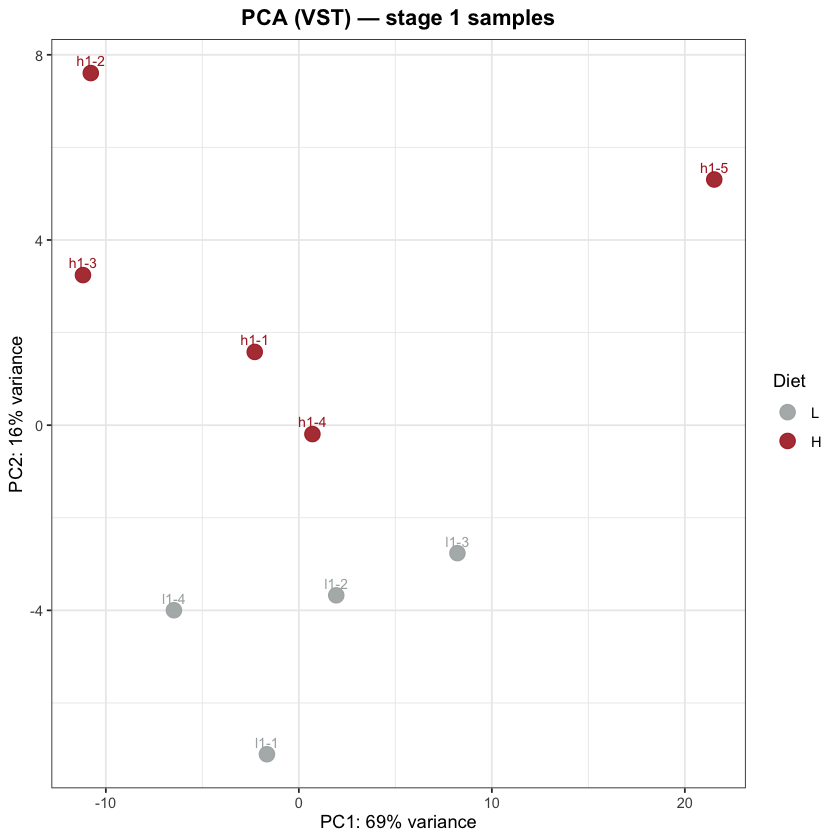

In [23]:
sample_ids <- colnames(results$dds)
stage1 <- sample_ids[grepl("^[hl]1-", sample_ids)]
if (length(stage1) == 0) stop("No h1- / l1- samples in results$dds")
vsd <- vst(results$dds, blind = FALSE)
vsd1 <- vsd[, stage1]
pca_data <- plotPCA(vsd1, intgroup = "group", returnData = TRUE)
pca_data$hl <- factor(ifelse(grepl("^h", pca_data$name), "H", "L"), levels = c("L", "H"))
pct <- round(100 * attr(pca_data, "percentVar"))
ggplot(pca_data, aes(x = PC1, y = PC2, color = hl, label = name)) +
  geom_point(size = 4, alpha = 0.9) +
  geom_text(aes(label = name), vjust = -0.7, size = 3, show.legend = FALSE) +
  scale_color_manual(values = c(L = "#a9aeae", H = "#ab2426"), name = "Diet") +
  labs(
    title = "PCA (VST) — stage 1 samples",
    x = paste0("PC1: ", pct[1], "% variance"),
    y = paste0("PC2: ", pct[2], "% variance")
  ) +
  theme_bw() +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"))

In [24]:
# ── L1 vs H1: 4 LFD replicates (l1-5 excluded) + 5 HFD replicates ────────────

# 1. Build count matrix for l1 + h1 only (exclude l1-5)
count_files_all <- list.files("TEcounts_output", pattern = "\\.cntTable$", full.names = TRUE)
l1h1_files <- count_files_all[grepl("(l1|h1)-[1-4]\\.cntTable$", basename(count_files_all))]
l1h1_files <- l1h1_files[!grepl("l1-5\\.cntTable$", basename(l1h1_files))]

count_list <- lapply(l1h1_files, function(f) {
  d <- read.table(f, header = TRUE, sep = "\t")
  colnames(d) <- c("gene_id", "counts")
  d$gene_id <- gsub('"', '', d$gene_id)
  sn <- gsub("\\.cntTable$", "", basename(f))
  colnames(d)[2] <- sn
  d
})
cm <- Reduce(function(x, y) merge(x, y, by = "gene_id", all = TRUE), count_list)
cm[is.na(cm)] <- 0
rownames(cm) <- cm$gene_id; cm$gene_id <- NULL
cm <- as.matrix(cm)

# 2. Filter low counts
keep <- rowSums(cm >= 10) >= 2
cm <- cm[keep, ]
cat("Genes after filtering:", nrow(cm), "\n")
cat("Samples:", colnames(cm), "\n")

# 3. Metadata
meta <- data.frame(
  group = factor(ifelse(grepl("^l1", colnames(cm)), "LFD_1", "HFD_1")),
  row.names = colnames(cm)
)

# 4. DESeq2
dds2 <- DESeqDataSetFromMatrix(round(cm), meta, ~ group)
dds2$group <- relevel(dds2$group, ref = "LFD_1")
dds2 <- DESeq(dds2)

# 5. Results: HFD_1 relative to LFD_1
res2 <- as.data.frame(results(dds2, contrast = c("group", "HFD_1", "LFD_1"), alpha = 0.05))
res2$gene_id <- rownames(res2)
res2$padj[is.na(res2$padj)] <- 1
res2$log2FoldChange[is.na(res2$log2FoldChange)] <- 0
res2$significant <- res2$padj < 0.05

# 6. Attach gene names from the cached annotations
ann <- results$count_matrix_annotated[, c("gene_id", "external_gene_name",
                                          "category", "gene_biotype")]
res2 <- merge(res2, ann, by = "gene_id", all.x = TRUE)
res2$display_name <- ifelse(!is.na(res2$external_gene_name) & res2$external_gene_name != "",
                            res2$external_gene_name, res2$gene_id)

# 7. Sort and show top protein-coding DEGs
top_up <- res2 %>%
  filter(significant, category == "protein_coding", log2FoldChange > 0) %>%
  arrange(padj) %>%
  head(20) %>%
  dplyr::select(display_name, log2FoldChange, padj, gene_biotype)

top_dn <- res2 %>%
  filter(significant, category == "protein_coding", log2FoldChange < 0) %>%
  arrange(padj) %>%
  head(20) %>%
  dplyr::select(display_name, log2FoldChange, padj, gene_biotype)

cat("\n── Top 20 UP in HFD_1 vs LFD_1 ──\n"); print(top_up, row.names = FALSE)
cat("\n── Top 20 DOWN in HFD_1 vs LFD_1 ──\n"); print(top_dn, row.names = FALSE)

# 8. Save full results
dir.create("RNAseq_results/DEG", showWarnings = FALSE, recursive = TRUE)
write.csv(res2[order(res2$padj), ],
          "RNAseq_results/DEG/LFD1_vs_HFD1_all.csv", row.names = FALSE)
cat("\nSaved to RNAseq_results/DEG/LFD1_vs_HFD1_all.csv\n")

Genes after filtering: 27108 
Samples: h1-1 h1-2 h1-3 h1-4 l1-1 l1-2 l1-3 l1-4 


converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing




── Top 20 UP in HFD_1 vs LFD_1 ──
         display_name log2FoldChange         padj           gene_biotype
                 Rptn      1.7233828 1.868781e-21         protein_coding
               Trarg1      0.9538615 1.775349e-11         protein_coding
               Sprr2b      1.9129319 1.321431e-10         protein_coding
               S100a9      2.2266618 1.957751e-09         protein_coding
                 Mest      0.7949455 2.991609e-08         protein_coding
               Pmepa1      0.6062379 7.571842e-08         protein_coding
               Sprr2d      1.4252021 3.943314e-07         protein_coding
                 Atf3      1.6160907 9.057440e-07         protein_coding
               Lhfpl2      0.5221800 1.100545e-06         protein_coding
                Fabp3      1.2113191 2.358303e-06         protein_coding
             Ifi27l2a      0.9405558 2.358303e-06         protein_coding
                Alox8      1.2959327 3.396741e-06         protein_coding
               G

Stage 1 samples used: h1-1, h1-2, h1-3, h1-4, l1-1, l1-2, l1-3, l1-4 


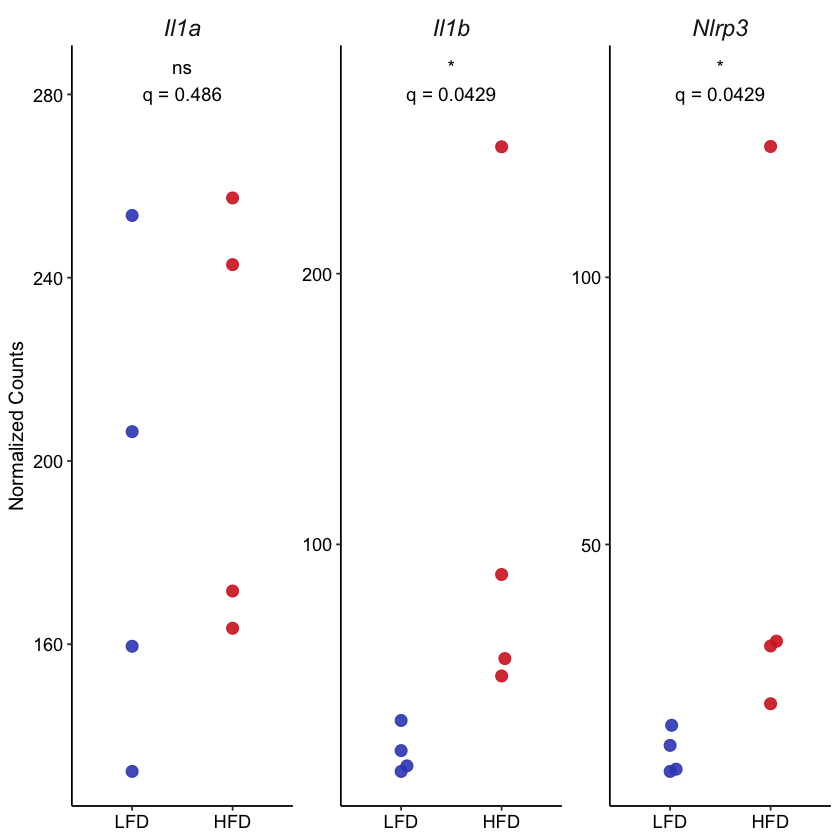

In [25]:
genes_of_interest <- c("Il1a", "Il1b", "Nlrp3")

# Use only stage 1 samples (h1-1..h1-4, l1-1..l1-4); exclude h1-5/l1-5
all_samples   <- colnames(results$dds)
stage1_samples <- all_samples[grepl("^[hl]1-[1-4]$", all_samples)]
cat("Stage 1 samples used:", paste(stage1_samples, collapse = ", "), "\n")

# DESeq2 normalized counts
norm_mat <- counts(results$dds, normalized = TRUE)[, stage1_samples]

ann <- results$count_matrix_annotated
get_ensembl_id <- function(gene_name) {
  hits <- ann$gene_id[!is.na(ann$external_gene_name) & ann$external_gene_name == gene_name]
  hits <- hits[hits %in% rownames(norm_mat)]
  if (length(hits) > 0) hits[1] else NA
}
gene_ids <- setNames(sapply(genes_of_interest, get_ensembl_id), genes_of_interest)
gene_ids <- gene_ids[!is.na(gene_ids)]

diet <- factor(ifelse(grepl("^h", stage1_samples), "HFD", "LFD"), levels = c("LFD", "HFD"))

df <- do.call(rbind, lapply(names(gene_ids), function(g) {
  data.frame(gene = g, sample = stage1_samples,
             norm_count = norm_mat[gene_ids[g], ], diet = diet)
}))
df$gene <- factor(df$gene, levels = genes_of_interest)

# Per-gene p-values (Wilcoxon)
pvals <- sapply(genes_of_interest, function(g) {
  d <- df[df$gene == g, ]
  wilcox.test(norm_count ~ diet, data = d)$p.value
})
sig_label <- ifelse(pvals < 0.001, "***",
              ifelse(pvals < 0.01,  "**",
              ifelse(pvals < 0.05,  "*", "ns")))

label_df <- data.frame(
  gene  = factor(genes_of_interest, levels = genes_of_interest),
  diet  = "LFD",
  label = paste0(sig_label, "\np = ", signif(pvals, 3)),
  y     = sapply(genes_of_interest, function(g) max(df$norm_count[df$gene == g]) * 1.1)
)

pvals_adj <- p.adjust(pvals, method = "BH")
sig_label <- ifelse(pvals_adj < 0.001, "***",
              ifelse(pvals_adj < 0.01,  "**",
              ifelse(pvals_adj < 0.05,  "*", "ns")))
label_df$label <- paste0(sig_label, "\nq = ", signif(pvals_adj, 3))

ggplot(df, aes(x = diet, y = norm_count, color = diet)) +
  geom_beeswarm(size = 3, alpha = 0.9, cex = 3) +
  geom_text(data = label_df, aes(x = 1.5, y = y, label = label),
            inherit.aes = FALSE, size = 4) +
  scale_color_manual(values = c(LFD = "#3b4cc0", HFD = "#d62728")) +
  facet_wrap(~ gene, scales = "free_y") +
  labs(x = NULL, y = "Normalized Counts") +
  theme_classic() +
  theme(
    legend.position = "none",
    strip.text = element_text(face = "italic", size = 14),
    strip.background = element_blank(),
    axis.text = element_text(color = "black", size = 11),
    axis.title.y = element_text(size = 12)
  )

Values for Extended Data Figure 7b

In [26]:
for (g in names(gene_ids)) {
  cat("\n---", g, "---\n")
  d <- df[df$gene == g, ]
  print(d[, c("sample", "diet", "norm_count")])
}


--- Il1a ---
     sample diet norm_count
h1-1   h1-1  HFD   171.6116
h1-2   h1-2  HFD   257.4141
h1-3   h1-3  HFD   242.8542
h1-4   h1-4  HFD   163.4877
l1-1   l1-1  LFD   206.3963
l1-2   l1-2  LFD   159.5509
l1-3   l1-3  LFD   132.2407
l1-4   l1-4  LFD   253.5829

--- Il1b ---
      sample diet norm_count
h1-11   h1-1  HFD   51.39171
h1-21   h1-2  HFD  246.86437
h1-31   h1-3  HFD   88.87430
h1-41   h1-4  HFD   57.81883
l1-11   l1-1  LFD   23.81495
l1-21   l1-2  LFD   18.17668
l1-31   l1-3  LFD   16.12692
l1-41   l1-4  LFD   34.93809

--- Nlrp3 ---
      sample diet norm_count
h1-12   h1-1  HFD  20.189599
h1-22   h1-2  HFD 124.487163
h1-32   h1-3  HFD  31.002661
h1-42   h1-4  HFD  31.900044
l1-12   l1-1  LFD   7.938318
l1-22   l1-2  LFD  16.157052
l1-32   l1-3  LFD   7.525895
l1-42   l1-4  LFD  12.397388


Stage 1 samples used: h1-1, h1-2, h1-3, h1-4, l1-1, l1-2, l1-3, l1-4 


converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



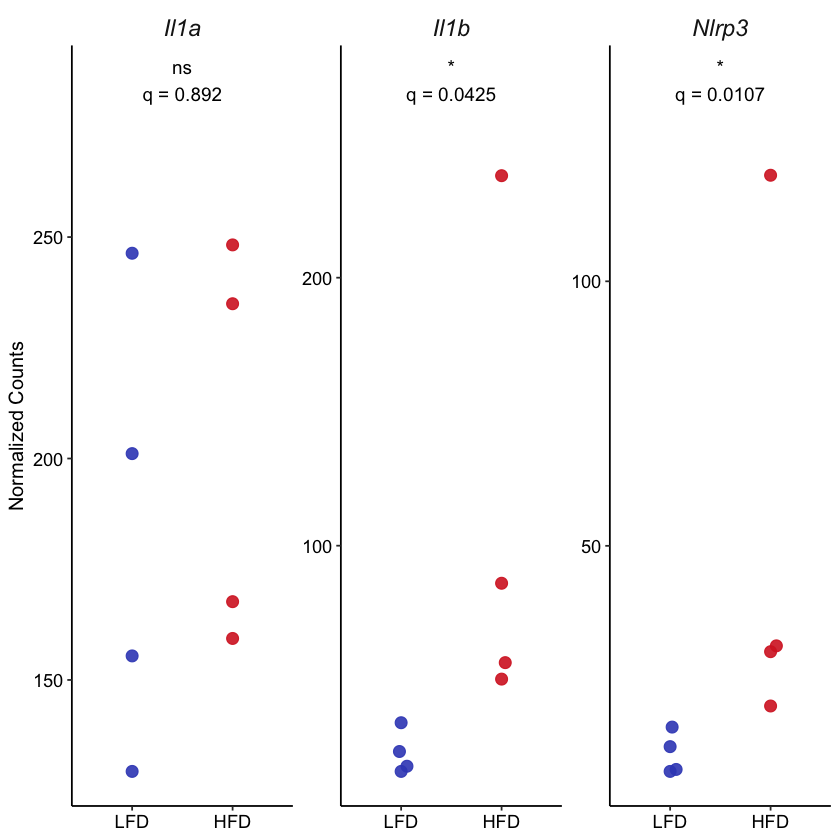

In [27]:
genes_of_interest <- c("Il1a", "Il1b", "Nlrp3")
stage      <- 1
drop_samples <- c("h1-5", "l1-5")
hfd_group  <- paste0("HFD_", stage)
lfd_group  <- paste0("LFD_", stage)

all_samples   <- colnames(results$dds)
sample_subset <- all_samples[colData(results$dds)$group %in% c(hfd_group, lfd_group)]
sample_subset <- setdiff(sample_subset, drop_samples)
cat("Stage 1 samples used:", paste(sample_subset, collapse = ", "), "\n")

raw_counts <- counts(results$dds, normalized = FALSE)[, sample_subset]
keep       <- rowSums(raw_counts >= 10) >= 2
raw_counts <- raw_counts[keep, ]
meta_sub   <- data.frame(
  group = factor(colData(results$dds)[sample_subset, "group"],
                 levels = c(lfd_group, hfd_group)),
  row.names = sample_subset
)
dds_sub <- DESeqDataSetFromMatrix(round(raw_counts), meta_sub, ~ group)
dds_sub <- DESeq(dds_sub)
res_s1  <- as.data.frame(results(dds_sub,
                                 contrast = c("group", hfd_group, lfd_group),
                                 alpha    = 0.05))
res_s1$padj[is.na(res_s1$padj)] <- 1

norm_mat <- counts(dds_sub, normalized = TRUE)

ann <- results$count_matrix_annotated
get_ensembl_id <- function(gene_name) {
  hits <- ann$gene_id[!is.na(ann$external_gene_name) & ann$external_gene_name == gene_name]
  hits <- hits[hits %in% rownames(norm_mat)]
  if (length(hits) > 0) hits[1] else NA
}
gene_ids <- setNames(sapply(genes_of_interest, get_ensembl_id), genes_of_interest)
gene_ids <- gene_ids[!is.na(gene_ids)]

padj_s1 <- setNames(res_s1$padj[match(gene_ids, rownames(res_s1))],           names(gene_ids))
lfc_s1  <- setNames(res_s1$log2FoldChange[match(gene_ids, rownames(res_s1))], names(gene_ids))

diet <- factor(ifelse(grepl("^h", sample_subset), "HFD", "LFD"), levels = c("LFD", "HFD"))

df <- do.call(rbind, lapply(names(gene_ids), function(g) {
  data.frame(gene = g, sample = sample_subset,
             norm_count = norm_mat[gene_ids[g], sample_subset], diet = diet)
}))
df$gene <- factor(df$gene, levels = genes_of_interest)

sig_label <- ifelse(padj_s1 < 0.001, "***",
              ifelse(padj_s1 < 0.01,  "**",
              ifelse(padj_s1 < 0.05,  "*", "ns")))

label_df <- data.frame(
  gene  = factor(names(gene_ids), levels = genes_of_interest),
  label = paste0(sig_label, "\nq = ", signif(padj_s1, 3)),
  y     = sapply(names(gene_ids), function(g) max(df$norm_count[df$gene == g]) * 1.15)
)


ggplot(df, aes(x = diet, y = norm_count, color = diet)) +
  geom_beeswarm(size = 3, alpha = 0.9, cex = 3) +
  geom_text(data = label_df, aes(x = 1.5, y = y, label = label),
            inherit.aes = FALSE, size = 4) +
  scale_color_manual(values = c(LFD = "#3b4cc0", HFD = "#d62728")) +
  facet_wrap(~ gene, scales = "free_y") +
  labs(x = NULL, y = "Normalized Counts") +
  theme_classic() +
  theme(
    legend.position = "none",
    strip.text = element_text(face = "italic", size = 14),
    strip.background = element_blank(),
    axis.text = element_text(color = "black", size = 11),
    axis.title.y = element_text(size = 12)
  )

Stage 2 samples used ( 10 ): h2-1, h2-2, h2-3, h2-4, h2-5, l2-1, l2-2, l2-3, l2-4, l2-5 


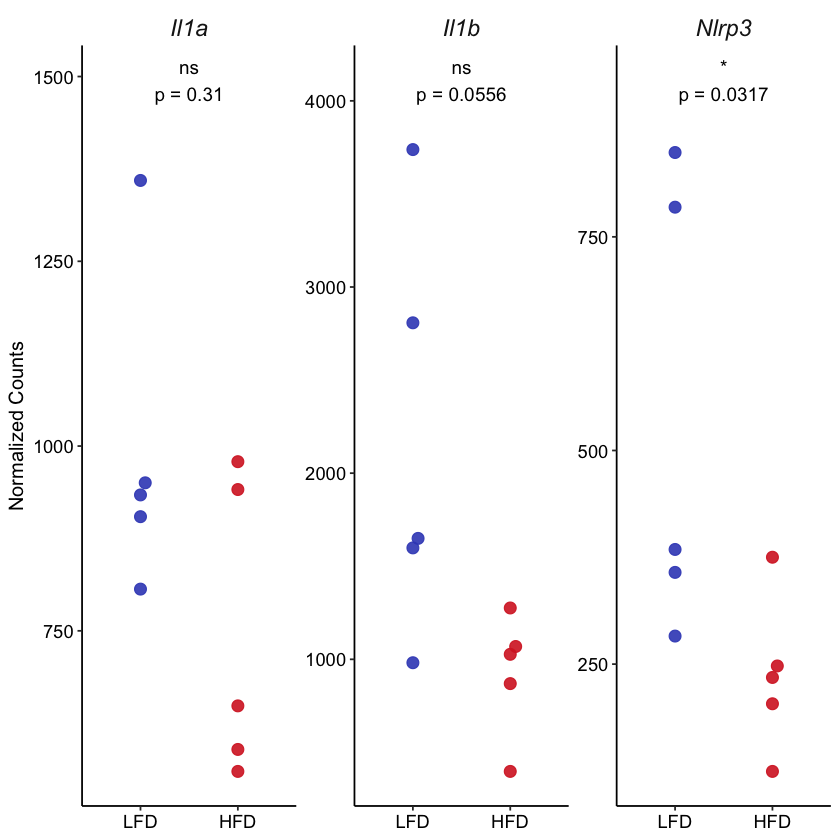

In [28]:
genes_of_interest <- c("Il1a", "Il1b", "Nlrp3")

# Stage 2: keep ALL 5 reps per diet
all_samples    <- colnames(results$dds)
stage2_samples <- all_samples[grepl("^[hl]2-[1-5]$", all_samples)]
cat("Stage 2 samples used (", length(stage2_samples), "):",
    paste(stage2_samples, collapse = ", "), "\n")


norm_mat <- counts(results$dds, normalized = TRUE)[, stage2_samples]

ann <- results$count_matrix_annotated
get_ensembl_id <- function(gene_name) {
  hits <- ann$gene_id[!is.na(ann$external_gene_name) & ann$external_gene_name == gene_name]
  hits <- hits[hits %in% rownames(norm_mat)]
  if (length(hits) > 0) hits[1] else NA
}
gene_ids <- setNames(sapply(genes_of_interest, get_ensembl_id), genes_of_interest)
gene_ids <- gene_ids[!is.na(gene_ids)]

diet <- factor(ifelse(grepl("^h", stage2_samples), "HFD", "LFD"), levels = c("LFD", "HFD"))

df <- do.call(rbind, lapply(names(gene_ids), function(g) {
  data.frame(gene = g, sample = stage2_samples,
             norm_count = norm_mat[gene_ids[g], ], diet = diet)
}))
df$gene <- factor(df$gene, levels = genes_of_interest)

pvals <- sapply(genes_of_interest, function(g) {
  d <- df[df$gene == g, ]
  wilcox.test(norm_count ~ diet, data = d)$p.value
})
sig_label <- ifelse(pvals < 0.001, "***",
              ifelse(pvals < 0.01,  "**",
              ifelse(pvals < 0.05,  "*", "ns")))

label_df <- data.frame(
  gene  = factor(genes_of_interest, levels = genes_of_interest),
  diet  = "LFD",
  label = paste0(sig_label, "\np = ", signif(pvals, 3)),
  y     = sapply(genes_of_interest, function(g) max(df$norm_count[df$gene == g]) * 1.1)
)

ggplot(df, aes(x = diet, y = norm_count, color = diet)) +
  geom_beeswarm(size = 3, alpha = 0.9, cex = 3) +
  geom_text(data = label_df, aes(x = 1.5, y = y, label = label),
            inherit.aes = FALSE, size = 4) +
  scale_color_manual(values = c(LFD = "#3b4cc0", HFD = "#d62728")) +
  facet_wrap(~ gene, scales = "free_y") +
  labs(x = NULL, y = "Normalized Counts") +
  theme_classic() +
  theme(
    legend.position = "none",
    strip.text = element_text(face = "italic", size = 14),
    strip.background = element_blank(),
    axis.text = element_text(color = "black", size = 11),
    axis.title.y = element_text(size = 12)
  )

In [29]:
for (g in names(gene_ids)) {
  cat("\n---", g, "---\n")
  d <- df[df$gene == g, ]
  print(d[, c("sample", "diet", "norm_count")])
}


--- Il1a ---
     sample diet norm_count
h2-1   h2-1  HFD   648.4811
h2-2   h2-2  HFD   559.7885
h2-3   h2-3  HFD   941.1867
h2-4   h2-4  HFD   978.8760
h2-5   h2-5  HFD   589.5175
l2-1   l2-1  LFD   806.4405
l2-2   l2-2  LFD  1359.3802
l2-3   l2-3  LFD   933.8862
l2-4   l2-4  LFD   950.2756
l2-5   l2-5  LFD   904.4678

--- Il1b ---
      sample diet norm_count
h2-11   h2-1  HFD  1275.8578
h2-21   h2-2  HFD  1068.9214
h2-31   h2-3  HFD  1026.9392
h2-41   h2-4  HFD   869.5548
h2-51   h2-5  HFD   397.8562
l2-11   l2-1  LFD  1649.5814
l2-21   l2-2  LFD  3738.2956
l2-31   l2-3  LFD  1598.5832
l2-41   l2-4  LFD  2807.7214
l2-51   l2-5  LFD   981.6902

--- Nlrp3 ---
      sample diet norm_count
h2-12   h2-1  HFD   375.0830
h2-22   h2-2  HFD   234.3900
h2-32   h2-3  HFD   247.8458
h2-42   h2-4  HFD   203.5982
h2-52   h2-5  HFD   124.4436
l2-12   l2-1  LFD   357.3449
l2-22   l2-2  LFD   848.6991
l2-32   l2-3  LFD   384.1827
l2-42   l2-4  LFD   784.7121
l2-52   l2-5  LFD   282.8272
